In [1]:
from pathlib import Path
import os, json, zipfile
root=Path('/workspace')
print('\n'.join(str(p) for p in root.iterdir()))

/workspace/settings.md
/workspace/.kernel_llm_logs_1.jsonl
/workspace/truth_tables.md
/workspace/compare.py
/workspace/.config
/workspace/tables.md
/workspace/compare_tables.md
/workspace/memory
/workspace/README.md
/workspace/density.json
/workspace/compare
/workspace/policies.py
/workspace/al_README.md
/workspace/.prompts
/workspace/quality
/workspace/truth_tables.json
/workspace/results
/workspace/landscape.py
/workspace/density.py
/workspace/bofn_alloy.py
/workspace/analyze.py
/workspace/needle.py
/workspace/lost+found
/workspace/needle.json
/workspace/landscape.json
/workspace/k1
/workspace/al_analyze.py
/workspace/al_bofn_alloy.py
/workspace/al_optimum.json
/workspace/al_policies.py
/workspace/.skills


In [2]:
for name in ['settings.md','al_README.md','README.md','compare_tables.md']:
 print('\n'+'='*35+' '+name+' '+'='*35+'\n'+(root/name).read_text())


=================================== settings.md ===================================
# Settings of the uploaded runs

- Python 3.12.3, torch 2.14.1+cpu, botorch 0.18.1, gpytorch 1.15.2; CPU only, one thread per run.
- pKGFN Monte Carlo (results/, code version 2026-10-27): S_ACQ = 64 base samples, N_CAND = 16 candidates per stage, N_POOL = 512 Sobol designs per iteration, 32 + 16 anchors (top posterior mean, top EI) plus every deposited design in the inner-max set (deduplicated), 24 perturbations of each of the 8 best pool designs (the aluminum benchmark's production settings); 10 Gauss-Hermite nodes for one-output stages, a 2-point product rule (16 points) for the four CALPHAD outputs. The first copper sweep (quality/results-light/) ran S_ACQ = 32, N_CAND = 10, N_POOL = 256, 24 + 12 anchors, 16 perturbations, with the fallback's EI test including the 1e-9 tie-break. Every run stores its settings.
- Corrosion-aware tiered screening (tiered_ni): the shortlist keeps only compositions with

In [3]:
print((root/'al_README.md').read_text()); print('\n=== README ===\n'+(root/'README.md').read_text());print('\n=== TABLES HEADER ===\n'+(root/'compare_tables.md').read_text()[:3300])

# BOFN preliminary results: does choosing the stage beat tiered screening?

Synthetic benchmark for the MS&T26 talk (issue 83). It tests the claim in the
abstract: cost-aware partial evaluation of the alloy DAG (pKGFN,
[Buathong et al., ICML 2024](https://proceedings.mlr.press/v235/buathong24a.html))
reaches good alloys with several times less money than tiered screening or
whole-pipeline BO.

## Bottom line

**Where the claim holds.** If CALPHAD's screening criterion misses a real effect, tiered screening caps out. In this benchmark that effect is Zr/Sc inoculation suppressing hot cracking (`kappa = 1`). The screen's shortlist leaves out the optimum, so it plateaus at 63% of the optimum by $100k, below random designs (68%).
- pKGFN reaches that level after $26.5k, against $99.5k for screening: **3.8× less spend** (90% bootstrap CI 2.0–5.7; 20 seeds). Two independent re-implementations of the bootstrap (Edison, Oct 5) put the interval at 2.1–5.7 and 2.0–5.6, so its endpoints are themse

In [4]:
print((root/'README.md').read_text()[:18000]);print('\nFILES\n');
for d in ['k1','results','quality','compare']:
 p=root/d; fs=list(p.rglob('*.json'));print(d,len(fs),[str(f.relative_to(root)) for f in fs[:8]])
for f in ['al_optimum.json','truth_tables.json','landscape.json','needle.json','density.json']:
 print('\n',f,(root/f).read_text()[:2200])

# BOFN on a copper/DED network: does choosing the stage beat tiered screening?

Copper and blown-powder DED version of [`../bofn-prelim/`](../bofn-prelim/README.md), the aluminum LPBF benchmark behind the MS&T26 preliminary results, built for the ONR YIP copper proposal (`near-term-submissions/onr-yip/onr-yip-technical-proposal-cu-ded.tex`, Figs. `fig:synth` and `fig:sim`; issue 205). It asks the same question on the copper workflow: with eight priced stages from a $10 calculation to a $3,100 deposition session, does cost-aware partial evaluation (pKGFN, [Buathong et al., ICML 2024](https://proceedings.mlr.press/v235/buathong24a.html)) reach good alloys with less money than tiered screening or whole-pipeline BO? `bofn-prelim/` and its 292 stored runs are unchanged.

<!-- RESULTS -->
## Bottom line

**The aluminum headline does not carry over.** On the copper network at `(kappa, eta) = (1, 1)` (both screens biased; 20 seeds of pKGFN, 20 to 20 of the others), the policy that chooses the 

In [5]:
out=root/'outputs';out.mkdir(exist_ok=True)
for d in ['k1','results','quality','compare']:
 fs=list((root/d).rglob('*.json'));print(d,len(fs),[str(f.relative_to(root)) for f in fs[:4]])
for f in ['al_optimum.json','truth_tables.json']:
 obj=json.loads((root/f).read_text());print(f,str(obj)[:1200])
f=next((root/'results/k1e1').glob('eifn_s*.json')); run=json.loads(f.read_text());print(f,run.keys());print(str(run)[:6000]);
print('QUALITY DIRS',list((root/'quality').iterdir()))

k1 164 ['k1/pkgfn_free_s13.json', 'k1/ei_s19.json', 'k1/pkgfn_free_s1.json', 'k1/eifn_s5.json']
results 142 ['results/k1e1/ei_s19.json', 'results/k1e1/eifn_s5.json', 'results/k1e1/eifn_s16.json', 'results/k1e1/eifn_s12.json']
quality 30 ['quality/results-light/k1e1/pkgfn_s19.json', 'quality/results-light/k1e1/pkgfn_s18.json', 'quality/results-light/k1e1/pkgfn_s8.json', 'quality/results-light/k1e1/pkgfn_s15.json']
compare 80 ['compare/results-nogate/k1e1/ei_s19.json', 'compare/results-nogate/k1e1/eifn_s5.json', 'compare/results-nogate/k1e1/eifn_s16.json', 'compare/results-nogate/k1e1/eifn_s12.json']
al_optimum.json {'kappa1': 0.6937387251384528}
truth_tables.json [{'kappa': 1.0, 'eta': 1.0, 'optimum': 0.492187251856002, 'x_opt': [0.434, 0.585, 0.5, 0.0, 0.643, 0.582, 0.343], 'nodes_opt': {'s': 0.728, 'f': 0.737, 'g': 0.408, 'h': 0.125, 'q': 0.81, 'rho_u': 0.794, 'rho_m': 0.932, 'beta': 0.153, 'U': 0.759, 'w': 0.884, 'm': 0.953}, 'burden_opt': 0.6093136765285487, 'optimum_fails_calphad_s

In [6]:
from collections import Counter,defaultdict
import numpy as np,pandas as pd
from scipy.stats import wilcoxon
for d in ['k1','results','quality','compare']:
 fs=list((root/d).rglob('*.json'));print(d,Counter(f.name.rsplit('_s',1)[0] for f in fs))
for p in [root/'k1/pkgfn_s0.json',root/'quality/results-light/k1e1/pkgfn_s0.json',root/'results/k1e1/tiered_ni_ref_s0.json']:
 r=json.loads(p.read_text());print('\n',p.relative_to(root),'keys',list(r));print('settings',r.get('settings'));print('rows',r['rows'][:2]);print('last',r['rows'][-1]);print('counts',r['counts']); print('build',r.get('builds',[None])[-1]);print('shortlist',r.get('shortlist'));print('wref',r.get('w_ref'))
# Independent extraction: last observation at or below budget, no interpolation or extrapolated purchases.
opt_al=json.loads((root/'al_optimum.json').read_text())['kappa1']
opt_cu=next(t['optimum'] for t in json.loads((root/'truth_tables.json').read_text()) if t['kappa']==1 and t['eta']==1)
opt_ng=next(t['optimum'] for t in json.loads((root/'landscape.json').read_text()) if 'no immersion' in t.get('truth',''))
def load_runs(folder):
 return { (r['kind'],int(r['seed'])):r for p in Path(folder).rglob('*.json') for r in [json.loads(p.read_text())] }
groups={'Al':load_runs(root/'k1'),'Cu':load_runs(root/'results/k1e1'),'Cu-light':load_runs(root/'quality/results-light/k1e1'),'No-gate':load_runs(root/'compare/results-nogate/k1e1')}
print('light kinds',Counter(k[0] for k in groups['Cu-light']))
def score_at(r,budget):
 rows=[v for v in r['rows'] if v['spent']<=budget+1e-7]
 return float(rows[-1]['best_validated'])
records=[]
for group,runs in groups.items():
 optimum=opt_al if group=='Al' else opt_ng if group=='No-gate' else opt_cu
 for (kind,seed),r in runs.items():
  for budget in [0,25000,50000,100000]:
   records.append(dict(group=group,policy=kind,seed=seed,budget=budget,score=score_at(r,budget),pct=100*score_at(r,budget)/optimum))
data=pd.DataFrame(records)
summ=data.groupby(['group','policy','budget']).pct.agg(['count','mean','std']);summ['sem']=summ['std']/np.sqrt(summ['count'])
print('Optima:',opt_al,opt_cu,opt_ng)
print(summ.loc[(slice(None),slice(None),100000),:].to_string())
data.to_csv(out/'independent_scores.csv',index=False);summ.to_csv(out/'independent_summary.csv')

k1 Counter({'pkgfn_free': 20, 'ei': 20, 'eifn': 20, 'tiered_naive': 20, 'pkgfn': 20, 'tiered': 20, 'eifn_reuse': 20, 'random': 20, 'pkgfn_la': 4})
results Counter({'eifn': 21, 'eifn_reuse': 21, 'ei': 20, 'tiered': 20, 'tiered_ni_ref': 20, 'random': 20, 'tiered_ni': 20})
quality Counter({'pkgfn': 30})
compare Counter({'ei': 20, 'eifn': 20, 'eifn_reuse': 20, 'random': 20})

 k1/pkgfn_s0.json keys ['kind', 'kappa', 'seed', 'budget', 'rows', 'counts', 'wall_s']
settings None
rows [{'spent': 0.0, 'rec': 0.028983532864717807, 'best_validated': 0.22817589012872885, 'rec_printed': 0.22817589012872885, 'action': 'init', 'x_rec': [0.1579, 0.2967, 0.2118, 0.0, 0.4213, 0.6263, 0.803]}, {'spent': 2500.0, 'rec': 0.22483714102501323, 'best_validated': 0.22817589012872885, 'rec_printed': 0.22817589012872885, 'action': 'L', 'x_rec': [0.4283, 0.1496, 0.2387, 0.0, 0.7204, 0.6033, 0.54]}]
last {'spent': 99630.0, 'rec': 0.6639824795759607, 'best_validated': 0.6052946407196008, 'rec_printed': 0.605294696942

light kinds Counter({'pkgfn': 20})
Optima: 0.6937387251384528 0.492187251856002 0.7450505056586048
                               count       mean        std       sem
group    policy        budget                                       
Al       ei            100000     20  83.830888  12.621547  2.822264
         eifn          100000     20  85.751277  18.608341  4.160951
         eifn_reuse    100000     20  89.953476  11.005340  2.460869
         pkgfn         100000     20  83.837496   8.212060  1.836272
         pkgfn_free    100000     20  81.577109  21.538615  4.816181
         pkgfn_la      100000      4  83.933159  14.057282  7.028641
         random        100000     20  68.397927  10.039117  2.244815
         tiered        100000     20  62.702711  10.322188  2.308111
         tiered_naive  100000     20  57.438431  15.233229  3.406253
Cu       ei            100000     20  14.420507  27.978573  6.256199
         eifn          100000     20  73.211743  32.744735  7.321945
    

In [7]:
print('\n'.join(str(p.relative_to(root)) for p in (root/'quality').rglob('*.json')))
print('\nRESULT DUPLICATES\n')
for p in (root/'results').rglob('*.json'):
 if 's20' in p.name or len(p.relative_to(root/'results').parts)>2:print(p)
print('\nAL POLICIES HEAD\n'+(root/'al_policies.py').read_text()[:5000]);print('\nCU HEAD\n'+(root/'policies.py').read_text()[:7000])
print('\nCOMPARE SCRIPT\n'+(root/'compare.py').read_text()[:18000])

quality/results-light/k1e1/pkgfn_s19.json
quality/results-light/k1e1/pkgfn_s18.json
quality/results-light/k1e1/pkgfn_s8.json
quality/results-light/k1e1/pkgfn_s15.json
quality/results-light/k1e1/pkgfn_s6.json
quality/results-light/k1e1/pkgfn_s13.json
quality/results-light/k1e1/pkgfn_s16.json
quality/results-light/k1e1/pkgfn_s11.json
quality/results-light/k1e1/pkgfn_s7.json
quality/results-light/k1e1/pkgfn_s4.json
quality/results-light/k1e1/pkgfn_s9.json
quality/results-light/k1e1/pkgfn_s10.json
quality/results-light/k1e1/pkgfn_s2.json
quality/results-light/k1e1/pkgfn_s14.json
quality/results-light/k1e1/pkgfn_s12.json
quality/results-light/k1e1/pkgfn_s5.json
quality/results-light/k1e1/pkgfn_s3.json
quality/results-light/k1e1/pkgfn_s0.json
quality/results-light/k1e1/pkgfn_s17.json
quality/results-light/k1e1/pkgfn_s1.json
quality/results-light/k0e0/pkgfn_s6.json
quality/results-light/k0e0/pkgfn_s11.json
quality/results-light/k0e0/pkgfn_s7.json
quality/results-light/k0e0/pkgfn_s4.json
quali

In [8]:
# Save a concise plan and a numbered source inventory for reproducibility.
(out/'analysis_plan.txt').write_text('1. Independently extract budget-censored demonstrated scores and paired statistics.\n2. Audit comparison formulas, policy and truth code.\n3. Execute truth counterfactuals, shortlist and gating audits, cost-standardized and seed analyses.\n4. Separate causal ablations from observational explanations; report missing fidelity runs.\n5. Write report.md and machine-readable evidence.\n')
for name in ['compare.py','policies.py','al_policies.py','bofn_alloy.py','al_bofn_alloy.py','landscape.py','needle.py','density.py']:
 text=(root/name).read_text();(out/(name+'.numbered.txt')).write_text('\n'.join(f'{i+1}: {l}' for i,l in enumerate(text.splitlines())))
print((root/'compare.py').read_text()[:13500])

"""Copper against aluminum: why the bofn-prelim headline does not carry over.

    python compare/landscape.py      # first: the two truths on random designs (landscape.json)
    python compare/compare.py        # tables.md and the compare_*.png figures

Tables: the two benchmarks' results side by side; the copper network with and without the
immersion gate (compare/results-nogate/, run with BOFN_NOGATE=1); pKGFN at the light Monte Carlo
settings of the first copper sweep (quality/results-light/) against the aluminum production
settings (results/); tiered screening against corrosion-aware tiered screening.
"""

from __future__ import annotations

import json
import sys
from pathlib import Path

import numpy as np

HERE = Path(__file__).parent
CU = HERE.parent
AL = CU.parent / "bofn-prelim"
sys.path.insert(0, str(CU))
from analyze import GRID, SHORT, at, cost_to, curve, fmt_cost, optimum  # noqa: E402

AL_OPT = json.loads((HERE / "al_optimum.json").read_text())["kappa1"]
LAND = json.loa

In [9]:
import ast
for file in ['policies.py','al_policies.py','bofn_alloy.py','al_bofn_alloy.py']:
 t=(root/file).read_text(); tree=ast.parse(t);print('\n',file,len(t.splitlines()))
 for node in tree.body:
  if isinstance(node,(ast.FunctionDef,ast.ClassDef)):print(node.lineno,node.end_lineno,node.name)
print('\nANALYZE\n'+(root/'analyze.py').read_text()[:5000]); print('\nCOMPARE FIDELITY\n'+(root/'compare.py').read_text()[7000:10200])


 policies.py 748
79 89 initial_data
92 94 eps_for
97 113 recommend
116 133 Recorder
136 138 w_gate
144 153 w_reference
156 158 network_ei_pool
162 167 expected_improvement
170 194 calphad_shortlist
197 198 lab_gp
201 202 lot_passed_utah
205 233 chain
236 278 run_funnel_stages
281 401 run_full_policy
405 701 run_pkgfn
704 748 run

 al_policies.py 415
49 58 initial_data
61 63 eps_for
66 82 recommend
85 103 Recorder
106 108 network_ei_pool
112 117 expected_improvement
120 131 calphad_shortlist
134 230 run_full_policy
234 402 run_pkgfn
405 415 run

 bofn_alloy.py 542
102 104 burden
107 112 transform
115 116 sig
120 180 AlloyTruth
183 185 gate
188 189 objective_from
192 200 _reference_m
209 254 TinyGP
257 263 node_input
270 289 Data
292 293 comp_key
296 436 Lab
439 442 design_of_build
446 519 Network
522 524 sobol
527 530 normal_qmc
533 537 gauss_hermite
540 542 local_perturb

 al_bofn_alloy.py 346
58 60 burden
64 106 AlloyTruth
113 154 TinyGP
157 162 node_input
166 184 Data
187 243 Lab
24

In [10]:
print('\nCU POLICIES 1-405\n'+'\n'.join((root/'policies.py').read_text().splitlines()[:405]))


CU POLICIES 1-405
"""Sampling policies compared on the synthetic copper/DED alloy network, all on equal $ budgets.

Every policy starts from the same data (CALPHAD on 32 compositions plus five
random designs carried through every stage, Utah included) and is scored by the
true objective of the best design deposited at Mines and carried through tensile
and immersion ("best alloy demonstrated"). Two secondary metrics: the printed
alloy the policy's own model ranks best (`rec_printed`) and, if BOFN_REC is set,
the paper's recommender (`rec`, the argmax of the network posterior mean).
"""

from __future__ import annotations

import hashlib
import os
import time

import torch

import bofn_alloy
from bofn_alloy import (
    COMP,
    COSTS,
    D,
    F_SAFE,
    FULL_COST,
    GROUPS,
    IA,
    IAL,
    IFE,
    IMN,
    INI,
    IPV,
    LAMBDA,
    M_FIRST,
    P_CAP,
    SPEC,
    AlloyTruth,
    Data,
    Lab,
    Network,
    TinyGP,
    burden,
    design_of_build,
    gauss_hermit

In [11]:
def excerpt(file,a,b):print('\n'.join(f'{i}: {line}' for i,line in enumerate((root/file).read_text().splitlines(),1) if a<=i<=b))
excerpt('policies.py',136,235);excerpt('policies.py',405,565)

136: def w_gate(d: Data):
137:     """The one-hour screen's gate: the top quartile of every screened build so far (seed builds included)."""
138:     return float(torch.tensor(d.obs["w"][1]).quantile(W_QUANTILE))
139: 
140: 
141: _W_REF = {}
142: 
143: 
144: def w_reference(truth: AlloyTruth):
145:     """One-hour screen index of the SCREEN_REF reference coupon deposited dense (its densest build over
146:     16,384 settings), as a lab would measure it alongside its builds; it passes immersion in every cell."""
147:     key = (truth.kappa, truth.eta)
148:     if key not in _W_REF:
149:         c = torch.tensor(bofn_alloy.REFERENCE[SCREEN_REF])
150:         apv = torch.quasirandom.SobolEngine(3, scramble=True, seed=0).draw(16384).double()
151:         o = truth.full(torch.cat([c.expand(apv.shape[0], 4), apv], -1))
152:         _W_REF[key] = float(o["w"][o["rho_m"].argmax()])
153:     return _W_REF[key]
154: 
155: 
156: def network_ei_pool(net, d, P, eps, best):
157:     smp = net.sample

In [12]:
excerpt('policies.py',405,487);excerpt('policies.py',561,701);excerpt('al_policies.py',234,402)

405: def run_pkgfn(truth, seed, budget, verbose=False, utah=True, screens=False, audit=False):
406:     """pKGFN over the eight stages. `utah=False` removes the small-DED stage (`mines_only`).
407:     `screens=True` makes it trust the screens (no atomizing a composition the CALPHAD crack
408:     screen rejects, no Mines session on a lot that has not passed the Utah density gate, no
409:     immersion on a build the one-hour screen stops); `audit=True` lets about one in ten stopped
410:     candidates go on anyway, plus those just either side of each cutoff (Advance 5)."""
411:     d, lab = initial_data(truth, seed)
412:     rec = Recorder(truth, d)
413:     net = Network(d)
414:     lab.net = net
415:     rec(net, 0, "init")
416:     g = torch.Generator().manual_seed(5000 + seed)
417:     gh_t, gh_w = gauss_hermite(10)
418:     w1 = gh_t.unsqueeze(-1)
419:     # 4-output CALPHAD fantasy: 2-point Gauss-Hermite product rule
420:     pm = torch.tensor([-1.0, 1.0])
421:     w4 = torch.ca

In [13]:
excerpt('policies.py',565,701);excerpt('al_policies.py',234,295);excerpt('bofn_alloy.py',1,208)

565:         kg_group = {"S+T": "T", "S+K+I": "I", "K+I": "I"}
566: 
567:         def z_U_hat(j):
568:             B, L, cal = binfo(j)
569:             beta_hat = float(net.gp["beta"].mean_raw(z_beta(j).unsqueeze(0))[0])
570:             return torch.tensor([cal["s"], B["rho_m"], beta_hat])
571: 
572:         def z_m_hat(j, beta_known):
573:             B, L, cal = binfo(j)
574:             beta = B["beta"] if beta_known else float(net.gp["beta"].mean_raw(z_beta(j).unsqueeze(0))[0])
575:             zc = torch.tensor([float(L["c"][INI]), float(L["c"][IAL]), float(L["c"][IFE]), B["rho_m"], beta])
576:             w_hat = float(net.gp["w"].mean_raw(zc.unsqueeze(0))[0])
577:             return torch.cat([zc, torch.tensor([w_hat])])
578: 
579:         build_cands("S+T", lambda j, B: B["beta"] is None, z_U_hat, 59_000)
580:         build_cands("S+K+I", lambda j, B: B["beta"] is None, lambda j: z_m_hat(j, False), 59_500)
581:         build_cands("K+I", lambda j, B: B["beta"] is not None and

In [14]:
excerpt('bofn_alloy.py',1,120);excerpt('bofn_alloy.py',296,436);excerpt('bofn_alloy.py',446,519);excerpt('al_policies.py',254,284)

1: """Cost-aware Bayesian optimization of a synthetic copper/DED alloy function network.
2: 
3: Copper/DED version of `benchmarks/bofn-prelim/bofn_alloy.py` (the aluminum LPBF
4: network behind the MS&T26 preliminary results), built for the ONR YIP copper
5: proposal (issue 205). Same question: does choosing *which stage to run next*
6: (pKGFN, Buathong et al. ICML 2024) beat tiered screening and full-pipeline BO
7: when stages cost $10 to $3,100 each?
8: 
9: Design vector x (all scaled to [0, 1]; copper is the balance):
10:     x0 Ni  0-30 wt%        x4 a  ultrasonic atomizer setting
11:     x1 Al  0-9.5 wt%       x5 P  laser power (Utah's MX-Lab capped at 0.5)
12:     x2 Fe  0-4.5 wt%       x6 v  travel speed
13:     x3 Mn  0-4 wt%
14: 
15: Function network (one GP per node, outputs feed children), eight priced stages:
16:     C  CALPHAD + heat flow (c)              -> s strengthening potential, f solidification
17:                                                index, g nucleant fra

In [15]:
import importlib.util,sys,time
print('dependencies',[(m,importlib.util.find_spec(m) is not None) for m in ['torch','botorch','gpytorch']])
issues=[]
for label,runs in groups.items():
 for k,r in runs.items():
  s=np.array([v['spent'] for v in r['rows']]);y=np.array([v['best_validated'] for v in r['rows']])
  if not (np.diff(s)>=0).all():issues.append((label,k,'spend order'))
  if not (np.diff(y)>=-1e-7).all():issues.append((label,k,'nonmonotone'))
  if s[-1]>r['budget']+1e-6:issues.append((label,k,'overspend',s[-1]))
  if not np.isfinite(y).all():issues.append((label,k,'nonfinite'))
print('Validation issues:',issues)
print('Main Cu cells:',Counter((r['kappa'],r['eta']) for r in groups['Cu'].values()))
manifest=[]
for folder in ['k1','results','quality','compare']:
 for p in (root/folder).rglob('*.json'):
  r=json.loads(p.read_text());manifest.append(dict(path=str(p.relative_to(root)),kind=r['kind'],seed=r['seed'],kappa=r.get('kappa'),eta=r.get('eta'),budget=r['budget'],spent=r['rows'][-1]['spent'],nrows=len(r['rows']),settings=r.get('settings')))
pd.DataFrame(manifest).to_json(out/'manifest.json',orient='records',indent=2)
print('Nonheadline main runs',[(m['path'],m['kappa'],m['eta']) for m in manifest if m['path'].startswith('results/') and (m['kappa'],m['eta'])!=(1,1)])
summ['se_author']=summ['std']*np.sqrt((summ['count']-1)/summ['count'])/np.sqrt(summ['count'])
def cells(group,kind):
 if (group,kind) not in summ.index.droplevel('budget'):return None
 q=summ.loc[(group,kind)]
 return [f"{q.loc[b,'mean']:.2f} ± {q.loc[b,'se_author']:.2f}" for b in [25000,50000,100000]]
for g in groups:
 print('\n',g)
 for k in sorted({k for k,s in groups[g]}):print(k,cells(g,k))

dependencies [('torch', True), ('botorch', False), ('gpytorch', False)]
Validation issues: [('Al', ('pkgfn_free', 1), 'overspend', np.float64(100010.0)), ('Al', ('pkgfn_free', 0), 'overspend', np.float64(100010.0))]
Main Cu cells: Counter({(1.0, 1.0): 140})
Nonheadline main runs [('results/k0e0/eifn_reuse_s0.json', 0.0, 0.0), ('results/k0e0/eifn_s0.json', 0.0, 0.0)]

 Al
ei ['48.46 ± 6.75', '63.23 ± 5.18', '83.83 ± 2.75']
eifn ['50.07 ± 6.08', '76.83 ± 4.57', '85.75 ± 4.06']
eifn_reuse ['60.97 ± 6.08', '73.84 ± 5.05', '89.95 ± 2.40']
pkgfn ['62.00 ± 5.21', '69.58 ± 3.45', '83.84 ± 1.79']
pkgfn_free ['51.21 ± 6.43', '60.60 ± 5.20', '81.58 ± 4.69']
pkgfn_la ['64.83 ± 10.51', '67.38 ± 10.82', '83.93 ± 6.09']
random ['52.20 ± 5.25', '61.05 ± 3.84', '68.40 ± 2.19']
tiered ['46.07 ± 4.97', '55.94 ± 3.46', '62.70 ± 2.25']
tiered_naive ['44.52 ± 5.30', '51.60 ± 4.21', '57.44 ± 3.32']

 Cu
ei ['5.68 ± 3.33', '7.18 ± 3.22', '14.42 ± 6.10']
eifn ['14.98 ± 5.60', '38.77 ± 8.89', '73.21 ± 7.14']
ei

tiered ['-9.43 ± 5.36', '-9.11 ± 5.33', '-7.69 ± 5.23']
tiered_ni ['-6.64 ± 5.36', '0.76 ± 5.40', '10.22 ± 6.22']
tiered_ni_ref ['7.86 ± 4.12', '16.14 ± 3.86', '24.23 ± 4.63']

 Cu-light
pkgfn ['11.95 ± 6.39', '27.44 ± 7.20', '58.55 ± 4.72']

 No-gate
ei ['38.95 ± 5.80', '48.80 ± 5.39', '65.16 ± 4.49']
eifn ['43.73 ± 5.96', '66.78 ± 5.02', '84.77 ± 4.73']
eifn_reuse ['47.12 ± 5.51', '71.17 ± 3.45', '87.55 ± 2.14']
random ['43.25 ± 4.43', '47.33 ± 3.53', '50.87 ± 3.22']


In [16]:
import subprocess
res=subprocess.run([sys.executable,'-m','pip','install','botorch','gpytorch','--quiet'],capture_output=True,text=True)
print('pip returncode',res.returncode);print(res.stderr[-1500:])

pip returncode 0



In [17]:
import torch, importlib.util
# Load aluminum truth by path under a distinct name; policies import remains copper.
torch.set_num_threads(1)
spec=importlib.util.spec_from_file_location('al_truth_independent',root/'al_bofn_alloy.py');al=importlib.util.module_from_spec(spec);sys.modules[spec.name]=al;spec.loader.exec_module(al)
import bofn_alloy as cu
import policies as pol
print('Versions',torch.__version__)
print('Costs',al.COSTS,cu.COSTS,'m_ref',cu.M_REF)
print('Truth+Lab constants',cu.F_SAFE,cu.F_CRACK,cu.NOGATE)
print('Lab methods\n'+'\n'.join((root/'bofn_alloy.py').read_text().splitlines()[295:436]))
print('Tiny GP\n'+'\n'.join((root/'bofn_alloy.py').read_text().splitlines()[208:255]))

Versions 2.10.0+cpu
Costs {'C': 10.0, 'A': 1500.0, 'L': 2500.0, 'T': 200.0} {'C': 10.0, 'A': 400.0, 'U': 500.0, 'M': 1500.0, 'S': 100.0, 'T': 200.0, 'K': 50.0, 'I': 400.0} m_ref 0.8491354040681073
Truth+Lab constants 0.34 0.56 False
Lab methods
class Lab:
    """Runs stages against the truth, enforcing upstream requirements and costs."""

    def __init__(self, truth: AlloyTruth, data: Data):
        self.t, self.d = truth, data
        self.net = None  # the policy's current network model, used to estimate rho_u for a Mines run without a matching Utah run

    def _pay(self, group, amount=None):
        self.d.spent += COSTS[group] if amount is None else amount
        self.d.log.append((group, self.d.spent))

    def calphad(self, c):
        key = comp_key(c)
        if key in self.d.calphad:
            return self.d.calphad[key]
        out = {n: float(self.t.node(n, c)) for n in GROUPS["C"]}
        for n, v in out.items():
            self.d.add(n, c, v)
        self.d.calphad[k

In [18]:
# A fresh 10^6-design sample, chunked to keep memory modest; no supplied landscape routines used.
t0=time.time();ta,tc=al.AlloyTruth(1.),cu.AlloyTruth(1.,1.)
g=torch.Generator().manual_seed(641207)
rand_parts=[]
for _ in range(10):
 X=torch.rand(100000,7,generator=g);oa=ta.full(X);oc=tc.full(X)
 ya=ta.objective(X);yc=tc.objective(X,oc);yn=oc['U']-cu.LAMBDA*cu.burden(X)
 # Hold composition and beta fixed, set density to 1 in the corrosion equation.
 zi=cu.node_input('m',X,oc).clone();zi[:,3]=1.;mdense=tc.node('m',zi)
 rand_parts.append(np.column_stack([ya.numpy()/opt_al,yc.numpy()/opt_cu,yn.numpy()/opt_ng,oc['m'].numpy(),mdense.numpy(),oc['rho_m'].numpy(),X[:,0].numpy()]))
R=np.concatenate(rand_parts);np.savez_compressed(out/'fresh_random_truth_sample.npz',values=R)
truth_audit=[]
for j,name in enumerate(['Al','Cu','No-gate']):
 y=R[:,j];truth_audit.append(dict(truth=name,median_pct=100*np.median(y),positive_pct=100*np.mean(y>0),above60_pct=100*np.mean(y>=.6),above80_pct=100*np.mean(y>=.8)))
print(pd.DataFrame(truth_audit).to_string(index=False))
print('Immersion pass, dense counterfactual, rho>=.9:',100*(R[:,3]>=cu.M_REF).mean(),100*(R[:,4]>=cu.M_REF).mean(),100*(R[:,5]>=.9).mean())
print('Low Ni (<6 wt%) pass:',int(((R[:,6]<.2)&(R[:,3]>=cu.M_REF)).sum()))
print('fresh 60% rarity ratio',np.mean(R[:,0]>=.6)/np.mean(R[:,1]>=.6),'elapsed',time.time()-t0)
pd.DataFrame(truth_audit).to_csv(out/'fresh_truth_audit.csv',index=False)
# Random best-of-n expectation via independent repeated groups, no optimizer.
rng=np.random.default_rng(116)
for n in [5,21,24,26,29]:
 ix=rng.integers(len(R),size=(100000,n));print(n,np.max(R[ix,:3],axis=1).mean(0)*100)

  truth  median_pct  positive_pct  above60_pct  above80_pct
     Al  -17.271285       28.3597       3.2644       0.5090
     Cu  -41.554911        2.9772       0.2188       0.0118
No-gate  -20.738572       20.3718       0.7478       0.0325
Immersion pass, dense counterfactual, rho>=.9: 3.193 61.535799999999995 0.1512
Low Ni (<6 wt%) pass: 0
fresh 60% rarity ratio 14.919561243144425 elapsed 6.048263311386108
5 [ 28.45871987 -14.60258153  15.53243778]


21 [58.48439647  7.84541858 41.85455094]


24 [60.67609135 10.41512899 43.97060233]


26 [61.85182401 11.96687726 45.18318389]


29 [63.41227665 14.3488989  46.80802951]


In [19]:
# Independent paired tests, completion and first-positive audits.
def vals(group,policy,budget=100000):
 q=data[(data.group==group)&(data.policy==policy)&(data.budget==budget)].set_index('seed').pct
 return q.sort_index()
def paired(g1,k1,g2,k2,budget=100000):
 a,b=vals(g1,k1,budget),vals(g2,k2,budget);seeds=a.index.intersection(b.index);d=(a.loc[seeds]-b.loc[seeds]).values
 return dict(A=f'{g1}/{k1}',B=f'{g2}/{k2}',budget=budget,n=len(d),difference=d.mean(),wins=int((d>0).sum()),ties=int((d==0).sum()),losses=int((d<0).sum()),p=float(wilcoxon(d).pvalue) if np.any(d) else 1.)
prs=[]
for a,b in [('pkgfn','eifn'),('pkgfn','eifn_reuse'),('pkgfn','ei'),('pkgfn','random'),('pkgfn','tiered_ni_ref'),('tiered_ni_ref','tiered_ni'),('tiered_ni','tiered')]:
 ga='Cu-light' if a=='pkgfn' else 'Cu';gb='Cu-light' if b=='pkgfn' else 'Cu'
 for bud in [25000,50000,100000]:prs.append(paired(ga,a,gb,b,bud))
print(pd.DataFrame(prs).to_string(index=False));pd.DataFrame(prs).to_csv(out/'paired_tests.csv',index=False)
first=[];fb_audit=[]
all_cu={**groups['Cu'],**groups['Cu-light']}
for kind in sorted({k for k,s in all_cu}):
 runs=[r for (k,s),r in all_cu.items() if k==kind];hits=[];passhits=[];nb=na=fb=fa=0
 for r in runs:
  hits.append(next((v['spent'] for v in r['rows'] if v['best_validated']>0),np.inf))
  prev=r['rows'][0]['best_validated']
  for v in r['rows'][1:]:
   if 'fallback' in v:
    if prev<=0:nb+=1;fb+=int(v['fallback'])
    else:na+=1;fa+=int(v['fallback'])
   prev=v['best_validated']
 hh=np.array(hits);first.append(dict(policy=kind,start=sum(h==0 for h in hits),reach=int(np.isfinite(hh).sum()),median_all=np.median(hh),median_reachers=np.median(hh[np.isfinite(hh)]),median_new_reachers=np.median(hh[(hh>0)&np.isfinite(hh)]) if np.any((hh>0)&np.isfinite(hh)) else np.nan))
 if nb+na:print('Fallback pre-action (correct temporal split)',kind,fb,nb,fa,na)
print(pd.DataFrame(first).to_string(index=False));pd.DataFrame(first).to_csv(out/'first_positive.csv',index=False)
# Build outcomes, excluding the five sunk fully evaluated seed builds.
ba=[]
for kind in ['pkgfn','eifn','eifn_reuse','ei','random','tiered','tiered_ni','tiered_ni_ref']:
 runs=[r for (k,s),r in all_cu.items() if k==kind]
 b=[b for r in runs for b in r['builds'][5:]]
 dct={'policy':kind,'new_builds_per_run':len(b)/len(runs),'tensile_per_run':sum(x['U'] is not None for x in b)/len(runs),'immersed_per_run':sum(x['m'] is not None for x in b)/len(runs),'complete_per_run':sum(x['J'] is not None for x in b)/len(runs),'immersion_pass_per_run':sum(x['m'] is not None and x['m']>=cu.M_REF for x in b)/len(runs),'positive_failing_immersion':sum(x['J'] is not None and x['J']>0 and x['m']<cu.M_REF for x in b),'screenfail_per_run':sum(v['action']=='screen-fail' for r in runs for v in r['rows'])/len(runs),'utahfail_per_run':sum(v['action']=='utah-fail' for r in runs for v in r['rows'])/len(runs),'retired_per_run':sum(len(L['utah'])>=3 and max(u[2] for u in L['utah'])<.5 for r in runs for L in r['lots'][5:])/len(runs)}
 ba.append(dct)
print(pd.DataFrame(ba).to_string(index=False));pd.DataFrame(ba).to_csv(out/'build_audit.csv',index=False)

               A                B  budget  n  difference  wins  ties  losses        p
  Cu-light/pkgfn          Cu/eifn   25000 20   -3.025805     3     1      16 0.070157
  Cu-light/pkgfn          Cu/eifn   50000 20  -11.334027     6     0      14 0.230513
  Cu-light/pkgfn          Cu/eifn  100000 20  -14.659621     4     0      16 0.023951
  Cu-light/pkgfn    Cu/eifn_reuse   25000 20   -2.401649     4     2      14 0.156955
  Cu-light/pkgfn    Cu/eifn_reuse   50000 20   -4.834369     8     0      12 0.647655
  Cu-light/pkgfn    Cu/eifn_reuse  100000 20  -13.480522     2     0      18 0.009436
  Cu-light/pkgfn            Cu/ei   25000 20    6.270496     5     3      12 0.619154
  Cu-light/pkgfn            Cu/ei   50000 20   20.259457    12     0       8 0.019234
  Cu-light/pkgfn            Cu/ei  100000 20   44.131616    17     0       3 0.000048
  Cu-light/pkgfn        Cu/random   25000 20   12.562482    14     3       3 0.007482
  Cu-light/pkgfn        Cu/random   50000 20   20.5359

In [20]:
# Truth-rescore every stored build; verify records before using hidden outcomes counterfactually.
all_build_rows=[];truth_mismatches=[]
for (kind,seed),r in all_cu.items():
 for j,b in enumerate(r['builds']):
  x=torch.tensor(b['c']+[b['a']]+b['pv']);o=tc.full(x);jj=float(tc.objective(x,o))
  for n in ['rho_m','beta','U','w','m','J']:
   saved=b.get(n);actual=jj if n=='J' else float(o[n])
   if saved is not None and abs(actual-saved)>2e-4:truth_mismatches.append((kind,seed,j,n,saved,actual))
  all_build_rows.append(dict(policy=kind,seed=seed,build=j,new=j>=5,x=list(x.numpy()),Ni=30*b['c'][0],w=float(o['w']),m=float(o['m']),J=jj,rho=float(o['rho_m']),beta=float(o['beta']),screened=b['w'] is not None,immersed=b['m'] is not None,tensile=b['U'] is not None,complete=b['J'] is not None,pass_immersion=float(o['m'])>=cu.M_REF,w_ref=r.get('w_ref')))
bdf=pd.DataFrame(all_build_rows)
print('Truth mismatches > 2e-4',len(truth_mismatches),truth_mismatches[:4])
# Best demonstrated vs hidden best deposited: an upper bound, not an implementable policy.
ceil=[]
for kind in ['pkgfn','eifn','eifn_reuse','ei','random','tiered','tiered_ni','tiered_ni_ref']:
 a=bdf[bdf.policy==kind];a1=a[a.new];by=a.groupby('seed');hidden=by.J.max()*100/opt_cu
 passes=by.apply(lambda z: bool(z[z.complete].pass_immersion.any()),include_groups=False)
 c={'policy':kind,'demonstrated':vals('Cu-light' if kind=='pkgfn' else 'Cu',kind).mean(),'hidden_deposited_ceiling':hidden.mean(),'seeds_with_demonstrated_pass':passes.sum(),'hidden_new_passes':a1.pass_immersion.sum(),'hidden_new_positive':(a1.J>0).sum(),'new_completed':a1.complete.sum()}
 ceil.append(c)
print(pd.DataFrame(ceil).to_string(index=False));pd.DataFrame(ceil).to_csv(out/'deposition_ceiling.csv',index=False)
for kind in ['tiered','tiered_ni','tiered_ni_ref']:
 a=bdf[(bdf.policy==kind)&bdf.new];stopped=a[a.screened&~a.immersed]
 print('\n',kind,'stopped',len(stopped),'hidden pass',stopped.pass_immersion.sum(),'hidden positive',(stopped.J>0).sum(),'hidden good60',(stopped.J>=.6*opt_cu).sum(),'would pass ref',(stopped.w>=.706525133).sum())
 print('screened w quantiles',a.w.quantile([0,.25,.5,.75,1]).round(3).to_dict(),'m',a.m.quantile([0,.25,.5,.75,1]).round(3).to_dict())
 print('immersed: w range',a.loc[a.immersed,'w'].agg(['min','max']).to_dict(),'m range',a.loc[a.immersed,'m'].agg(['min','max']).to_dict())
bdf.drop(columns='x').to_csv(out/'build_truth_rescore.csv',index=False)

Truth mismatches > 2e-4 1 [('ei', 10, 5, 'w', 0.30368443527361016, 0.3034757365101296)]
       policy  demonstrated  hidden_deposited_ceiling  seeds_with_demonstrated_pass  hidden_new_passes  hidden_new_positive  new_completed
        pkgfn     58.552122                 68.495917                            18                352                  370            123
         eifn     73.211743                 73.211488                            17                150                  198            420
   eifn_reuse     72.032644                 72.032620                            17                222                  305            586
           ei     14.420507                 14.419805                             5                 31                  246            420
       random     22.292697                 22.295797                            16                 20                   23            420
       tiered     -7.690822                 -6.230200                         

In [21]:
# Audit shortlists, dynamic gates and fixed-composition process ceilings.
shortrows=[];gaterows=[];shortlists={};short_validation=[]
for kind in ['tiered','tiered_ni','tiered_ni_ref']:
 for seed in range(20):
  r=groups['Cu'][(kind,seed)]
  if 'shortlist' in r:cs=torch.tensor(r['shortlist'])
  else:
   dd,ll=pol.initial_data(tc,seed);cs,_,_,_=pol.calphad_shortlist(dd,ll,seed)
   short_validation.extend([min(float((torch.tensor(L['c'])-c).abs().max()) for c in cs) for L in r['lots'][5:]])
  shortlists[(kind,seed)]=cs
  for c in cs:
   f=float(tc.node('f',c));shortrows.append(dict(policy=kind,seed=seed,Ni=30*float(c[0]),Al=9.5*float(c[1]),Fe=4.5*float(c[2]),Mn=4*float(c[3]),f=f,calphad_pass=f<=cu.F_SAFE))
  ws=[b['w'] for b in r['builds'][:5]]
  for j,b in enumerate(r['builds'][5:],5):
   if b['w'] is None:continue
   ws.append(b['w']);gate=float(np.quantile(ws,.75));actualgate=r.get('w_ref') or gate
   gaterows.append(dict(policy=kind,seed=seed,build=j,relative_gate=gate,applied_gate=actualgate,w=b['w'],immersion=b['m'] is not None,pass_rule=b['w']>=actualgate-1e-12,would_pass_ref=b['w']>=.7065251330405741))
sdf=pd.DataFrame(shortrows);gdf=pd.DataFrame(gaterows)
print('Reconstructed original shortlist: max coordinate error against purchased lots',max(short_validation))
print(sdf.groupby('policy').agg(Ni_min=('Ni','min'),Ni_median=('Ni','median'),Ni_max=('Ni','max'),Al_median=('Al','median'),safe_fraction=('calphad_pass','mean')).to_string())
print('Seeds no safe shortlist',sdf.groupby(['policy','seed']).calphad_pass.sum().groupby('policy').apply(lambda a:int((a==0).sum())).to_dict())
print(gdf.groupby('policy').relative_gate.agg(['min','median','max']).to_string())
print('Gate reproduction disagreement',len(gdf[gdf.immersion!=gdf.pass_rule]))
print('Shortlists identical Ni variants:',all(groups['Cu'][('tiered_ni',s)]['shortlist']==groups['Cu'][('tiered_ni_ref',s)]['shortlist'] for s in range(20)))
sdf.to_csv(out/'shortlist_audit.csv',index=False);gdf.to_csv(out/'screen_gate_audit.csv',index=False)
process=cu.sobol(8192,3,seed=784)
short_opt=[]
for kind in ['tiered','tiered_ni']:
 for seed in range(20):
  cs=shortlists[(kind,seed)];xx=torch.cat([cs[:,None,:].expand(-1,len(process),-1),process[None,:,:].expand(len(cs),-1,-1)],-1).reshape(-1,7)
  yy=tc.objective(xx);j=int(yy.argmax());xb=xx[j].clone();yb=float(yy[j]);gg=torch.Generator().manual_seed(893+seed)
  for scale in [.06,.02,.006,.002]:
   pp=(xb[4:]+scale*torch.randn(4096,3,generator=gg)).clamp(0,1);xp=torch.cat([xb[:4].expand(len(pp),4),pp],-1);yp=tc.objective(xp);j=int(yp.argmax())
   if float(yp[j])>yb:xb,yb=xp[j],float(yp[j])
  short_opt.append(dict(policy=kind,seed=seed,best_pct=100*yb/opt_cu,x=xb.tolist()))
print(pd.DataFrame(short_opt).groupby('policy').best_pct.agg(['mean','min','median','max']).to_string())
pd.DataFrame(short_opt).to_json(out/'shortlist_oracle_process.json',orient='records',indent=2)

Reconstructed original shortlist: max coordinate error against purchased lots 4.900000000007676e-05
                 Ni_min  Ni_median    Ni_max  Al_median  safe_fraction
policy                                                                
tiered          1.31118   4.151625   6.47676   8.464856          1.000
tiered_ni      10.01400  11.493000  21.54900   0.674025          0.075
tiered_ni_ref  10.01400  11.493000  21.54900   0.674025          0.075
Seeds no safe shortlist {'tiered': 0, 'tiered_ni': 14, 'tiered_ni_ref': 14}
                    min    median       max
policy                                     
tiered         0.678798  0.789911  0.942369
tiered_ni      0.694641  0.759618  0.942369
tiered_ni_ref  0.692276  0.749716  0.942369
Gate reproduction disagreement 0
Shortlists identical Ni variants: True


                mean       min     median        max
policy                                              
tiered    -19.351041 -27.97604 -21.933626   3.890217
tiered_ni  60.468667  40.01759  61.518659  86.166860


In [22]:
for kind in ['tiered','tiered_ni','tiered_ni_ref']:
 r=groups['Cu'][(kind,0)];print(kind,r.keys(),r.get('shortlist'));print('lot0',r['lots'][5] if len(r['lots'])>5 else None)
print('elapsed baseline notebook ready')

tiered dict_keys(['kind', 'kappa', 'eta', 'seed', 'budget', 'm_ref', 'rows', 'counts', 'settings', 'gp_fits', 'builds', 'lots', 'w_gate_final', 'wall_s']) None
lot0 {'c': [0.1237, 0.8888, 0.8961, 0.8211], 'a': 0.9928679876029491, 'q': 0.032506026952516295, 'utah': [[0.5, 0.25, 0.23621391727773888]], 'sessions_left': 0}
tiered_ni dict_keys(['kind', 'kappa', 'eta', 'seed', 'budget', 'm_ref', 'rows', 'counts', 'settings', 'gp_fits', 'builds', 'lots', 'w_gate_final', 'shortlist', 'wall_s']) [[0.3347, 0.1213, 0.0523, 0.3095], [0.3536, 0.1804, 0.3028, 0.1442], [0.3364, 0.1357, 0.6322, 0.2411], [0.4194, 0.1549, 0.3289, 0.1064]]
lot0 {'c': [0.3347, 0.1213, 0.0523, 0.3095], 'a': 0.9906660644337535, 'q': 0.042148326028627704, 'utah': [[0.5, 0.25, 0.2643679794385548], [0.5, 0.45, 0.283478112388259]], 'sessions_left': 0}
tiered_ni_ref dict_keys(['kind', 'kappa', 'eta', 'seed', 'budget', 'm_ref', 'rows', 'counts', 'settings', 'gp_fits', 'builds', 'lots', 'w_gate_final', 'shortlist', 'w_ref', 'wall_

In [23]:
excerpt('al_policies.py',134,235)
for kind in ['ei','eifn','random']:
 print('Al',kind,'count ranges',[groups['Al'][(kind,s)]['counts'] for s in [0,1]],'rows last',[(groups['Al'][(kind,s)]['rows'][-1]['spent'],len(groups['Al'][(kind,s)]['rows'])-1) for s in [0,1]])
print('Al full spend first',[v['spent'] for v in groups['Al'][('random',0)]['rows'][:5]])
print('Al Lab full\n'+'\n'.join((root/'al_bofn_alloy.py').read_text().splitlines()[185:244]))

134: def run_full_policy(kind, truth, seed, budget):
135:     d, lab = initial_data(truth, seed)
136:     rec = Recorder(truth, d)
137:     net = Network(d)
138:     rec(net, 0, "init")
139:     g = torch.Generator().manual_seed(3000 + seed)
140:     it = 0
141:     if kind.startswith("tiered"):
142:         shortlist = calphad_shortlist(d, lab, seed)
143:         net = Network(d)
144:         it += 1
145:         rec(net, it, "C-screen")
146:     reuse = kind in ("tiered", "tiered_pu", "eifn_reuse")
147:     cheapest = COSTS["L"] + COSTS["T"] if reuse else COSTS["A"] + COSTS["L"] + COSTS["T"] + COSTS["C"]
148:     while d.spent + cheapest <= budget:
149:         it += 1
150:         X = torch.stack([x for x, _ in d.full])
151:         y = torch.tensor([v for _, v in d.full])
152:         if kind == "eifn_reuse":
153:             # ablation: network EI per dollar over new designs and reprints of
154:             # existing powders (partial evaluation without KG's stage choice)
155:    

In [24]:
# Cost-standardized check: truncate Al full-pipeline trajectories after the same 21 new full evaluations.
costcheck=[]
for k in ['ei','eifn','random']:
 a21=np.array([groups['Al'][(k,s)]['rows'][21]['best_validated']/opt_al*100 for s in range(20)])
 a23=vals('Al',k).values;c21=vals('Cu',k).values;ng=vals('No-gate',k).values
 costcheck.append(dict(policy=k,Al_23=a23.mean(),Al_21=a21.mean(),Cu_21=c21.mean(),cost_cycle_loss=a23.mean()-a21.mean(),total_drop=a23.mean()-c21.mean(),gate_ablation_gain=ng.mean()-c21.mean(),gate_share=(ng.mean()-c21.mean())/(a23.mean()-c21.mean())))
print(pd.DataFrame(costcheck).to_string(index=False));pd.DataFrame(costcheck).to_csv(out/'cost_and_gate_decomposition.csv',index=False)
# Count bookkeeping and fidelity summary, independently.
light=[r for (k,s),r in groups['Cu-light'].items() if k=='pkgfn']
fb=sum(v.get('fallback',False) for r in light for v in r['rows'][1:]);purchases=sum(len(r['rows'])-1 for r in light)
print('Light fallback',fb,purchases,fb/purchases)
print('Light counts',{k:np.mean([r['counts'][k] for r in light]) for k in cu.COSTS})
for target in [.6,.7]:
 hits=np.array([next((v['spent'] for v in r['rows'] if v['best_validated']>=target*opt_cu),np.inf) for r in light]);print('target',target,'median all',np.median(hits),'reached',np.isfinite(hits).sum(),'median reachers',np.median(hits[np.isfinite(hits)]))
# Original compare's post-purchase fallback split, independently to list the discrepancy.
for pre in [False,True]:
 counts=np.zeros((2,2),int)
 for r in light:
  for prev,v in zip(r['rows'],r['rows'][1:]):
   which=0 if (prev if pre else v)['best_validated']<=0 else 1;counts[which]+=[int(v['fallback']),1]
 print('fallback split pre?',pre,counts.tolist())
# Reconstruct sunk seed data and verify scores agree, without using any acquisition routine.
seeds=[]
for seed in range(20):
 g=torch.Generator().manual_seed(2000+seed);X=torch.rand(5,7,generator=g)
 ya=ta.objective(X);oc=tc.full(X);yc=tc.objective(X,oc);yn=oc['U']-.3*cu.burden(X)
 seeds.append([float(ya.max())/opt_al*100,float(yc.max())/opt_cu*100,float(yn.max())/opt_ng*100])
print('Re-executed seed means',np.mean(seeds,0),'max score error',np.max(np.abs(np.array(seeds)[:,1]-vals('Cu','random',0).values)))
# Over-budget Al any-alloy rows: do they change the demonstrated result?
for seed in [0,1]:
 r=groups['Al'][('pkgfn_free',seed)];print('over budget',seed,r['rows'][-2]['spent'],r['rows'][-1]['spent'],r['rows'][-1]['best_validated']-r['rows'][-2]['best_validated'])

policy     Al_23     Al_21     Cu_21  cost_cycle_loss  total_drop  gate_ablation_gain  gate_share
    ei 83.830888 80.492828 14.420507         3.338059   69.410381           50.735887    0.730955
  eifn 85.751277 85.033211 73.211743         0.718066   12.539534           11.562432    0.922078
random 68.397927 64.763245 22.292697         3.634683   46.105231           28.574528    0.619768
Light fallback 418 1944 0.21502057613168724
Light counts {'C': np.float64(6.7), 'A': np.float64(12.45), 'U': np.float64(11.3), 'M': np.float64(40.5), 'S': np.float64(15.7), 'T': np.float64(7.2), 'K': np.float64(14.0), 'I': np.float64(12.85)}
target 0.6 median all 85385.0 reached 12 median reachers 54465.0
target 0.7 median all inf reached 7 median reachers 59400.0
fallback split pre? False [[380, 893], [38, 1051]]
fallback split pre? True [[380, 907], [38, 1037]]
Re-executed seed means [34.91963803 -9.6095549  22.51827841] max score error 7.105427357601002e-15
over budget 0 98500.0 100010.0 0.0
over b

In [25]:
from e14c.web import web_search, cite_doi, fetch_parsed_page,save_citation
webhits=await web_search('additive manufacturing porosity lack of fusion keyhole processing maps copper directed energy deposition tensile strength porosity',num_results=4)
for h in webhits:print(h['title'],h['url'],h.get('snippet','')[:1800])

Influence of the laser power and powder feed rate on the porosity, dilution, and building efficiency of pure copper parts fabricated via directed energy deposition with a blue laser https://doi.org/10.1007/s00170-024-14789-w ## Abstract

We examined single- and multilayer formations in the directed energy deposition for manufacturing pure copper parts using a blue laser with a wavelength of 445 nm. We investigated the influence of laser power and hatching pitch on the surface quality of single-layer structures as well as evaluated the porosity and dilution of multilayer structures fabricated at various laser powers and powder feed rates using energy-dispersive X-ray spectrometry. In addition, the applicability of the simplified method based on the ratio of the built height and penetration depth to the AM process has been examined, and the predicted elemental content was compared with the results obtained from the SEM–EDS analysis. Based on these findings, a range of building conditions

In [26]:
# This local workspace has no PROJECT_ID; use the actual session UUID solely as a local citation-folder namespace.
os.environ.setdefault('PROJECT_ID',os.environ['TRAJECTORY_ID'])
bib1=await cite_doi('10.1007/s00170-024-14789-w');print(bib1)
bib2=await cite_doi('10.1038/s41467-024-45913-9');print(bib2)
import requests
resp=requests.get('https://proceedings.mlr.press/v235/buathong24a.html',timeout=45)
print('PMLR status',resp.status_code)
from bs4 import BeautifulSoup
pkgpage=BeautifulSoup(resp.text,'html.parser').get_text(' ',strip=True) if resp.status_code==200 else ''
print(pkgpage[:15000])

@article{Yamaguchi_2024, title={Influence of the laser power and powder feed rate on the porosity, dilution, and building efficiency of pure copper parts fabricated via directed energy deposition with a blue laser}, volume={135}, ISSN={1433-3015}, url={http://dx.doi.org/10.1007/s00170-024-14789-w}, DOI={10.1007/s00170-024-14789-w}, number={11-12}, journal={The International Journal of Advanced Manufacturing Technology}, publisher={Springer Science and Business Media LLC}, author={Yamaguchi, Mitsugu and Kato, Naoki and Funada, Yoshinori and Yachi, Taisei and Saikai, Ayahito and Furumoto, Tatsuaki}, year={2024}, month=Nov, pages={5235–5251} }


@article{Zhang_2024, title={Pore evolution mechanisms during directed energy deposition additive manufacturing}, volume={15}, ISSN={2041-1723}, url={http://dx.doi.org/10.1038/s41467-024-45913-9}, DOI={10.1038/s41467-024-45913-9}, number={1}, journal={Nature Communications}, publisher={Springer Science and Business Media LLC}, author={Zhang, Kai and Chen, Yunhui and Marussi, Sebastian and Fan, Xianqiang and Fitzpatrick, Maureen and Bhagavath, Shishira and Majkut, Marta and Lukic, Bratislav and Jakata, Kudakwashe and Rack, Alexander and Jones, Martyn A. and Shinjo, Junji and Panwisawas, Chinnapat and Leung, Chu Lun Alex and Lee, Peter D.}, year={2024}, month=Feb }


PMLR status 200
Bayesian Optimization of Function Networks with Partial Evaluations Proceedings of Machine Learning Research Volume 235 JMLR DMLR TMLR MLOSS FAQ Submission Format [ edit ] Bayesian Optimization of Function Networks with Partial Evaluations Poompol Buathong, Jiayue Wan, Raul Astudillo, Sam Daulton, Maximilian Balandat, Peter I. Frazier Proceedings of the 41st International Conference on Machine Learning , PMLR 235:4752-4784, 2024. Abstract Bayesian optimization is a powerful framework for optimizing functions that are expensive or time-consuming to evaluate. Recent work has considered Bayesian optimization of function networks (BOFN), where the objective function is given by a network of functions, each taking as input the output of previous nodes in the network as well as additional parameters. Leveraging this network structure has been shown to yield significant performance improvements. Existing BOFN algorithms for general-purpose networks evaluate the full network at

In [27]:
print({k:v for k,v in os.environ.items() if any(s in k for s in ['PROJECT','TRAJECTORY','WORKSPACE','PERSONA'])})
print('memory files',list((root/'memory').glob('*'))[:10]);print('prompts',[(p.name,p.read_text()[:1500]) for p in (root/'.prompts').glob('*.md')])

{'WORKSPACE_DIR': '/workspace', 'GCP_VERTEX_PROJECT_ID': 'crow-prod-451317', 'SANDBOX_WORKSPACE_SIZE': '50Gi', 'TRAJECTORY_ID': '009f44cb-d47e-42ba-8cb7-c279768d14ca', 'WORKSPACE_PATH': '/workspace'}
memory files [PosixPath('/workspace/memory/009f44cb-d47e-42ba-8cb7-c279768d14ca_memory_heron_c0_20261027T192407853747.jsonl')]
prompts [('MEMORY.md', "# Project Memory\n\n## Instructions\n\nEdit this file (`{prompt_path}`) to persist procedural and workflow patterns specific to this project: output formats, delivery channels, and recurring conventions. Do not record scientific findings or research outputs here. Update or remove entries as the project's conventions evolve.\n\n## Context\n\n[Fill me in]\n\n## Notes\n\n[Fill me in]\n"), ('USER.md', "# User\n\nEdit this file (`./.prompts/USER.md`) to remember stable facts about the user\nthat should persist across turns and sessions: how collaborative they want you\nto be, autonomy preferences, cadence and check-in expectations, voice and tone

In [28]:
import re
method_bib=re.search(r'@InProceedings\{.*?\n\}',pkgpage,re.S).group(0)
method_citation=save_citation(method_bib);print(method_citation)
# Source text retained as retrieved evidence; citations already saved through the required API.
for doi,name in [('10.1007/s00170-024-14789-w','copper_ded_porosity'),('10.1038/s41467-024-45913-9','ded_pore_mechanisms')]:
 rr=requests.get('https://doi.org/'+doi,timeout=45)
 tx=BeautifulSoup(rr.text,'html.parser').get_text(' ',strip=True)
 (out/(name+'_source.txt')).write_text(tx)
 print(name,rr.status_code,tx[tx.find('Abstract'):tx.find('Abstract')+1800])
(out/'method_source.txt').write_text(pkgpage)
(out/'references.bib').write_text(bib1+'\n'+bib2+'\n'+method_bib+'\n')

/workspace/citations/009f44cb-d47e-42ba-8cb7-c279768d14ca/009f44cb-d47e-42ba-8cb7-c279768d14ca.bib


copper_ded_porosity 200 Abstract We examined single- and multilayer formations in the directed energy deposition for manufacturing pure copper parts using a blue laser with a wavelength of 445 nm. We investigated the influence of laser power and hatching pitch on the surface quality of single-layer structures as well as evaluated the porosity and dilution of multilayer structures fabricated at various laser powers and powder feed rates using energy-dispersive X-ray spectrometry. In addition, the applicability of the simplified method based on the ratio of the built height and penetration depth to the AM process has been examined, and the predicted elemental content was compared with the results obtained from the SEM–EDS analysis. Based on these findings, a range of building conditions that reduce the dilution, suppress the porosity, and improve the building efficiency of the built parts was established. We found that a good surface quality of the single-layer structure was obtained at 

ded_pore_mechanisms 200 Abstract Porosity in directed energy deposition (DED) deteriorates mechanical performances of components, limiting safety-critical applications. However, how pores arise and evolve in DED remains unclear. Here, we reveal pore evolution mechanisms during DED using in situ X-ray imaging and multi-physics modelling. We quantify five mechanisms contributing to pore formation, migration, pushing, growth, removal and entrapment: (i) bubbles from gas atomised powder enter the melt pool, and then migrate circularly or laterally; (ii) small bubbles can escape from the pool surface, or coalesce into larger bubbles, or be entrapped by solidification fronts; (iii) larger coalesced bubbles can remain in the pool for long periods, pushed by the solid/liquid interface; (iv) Marangoni surface shear flow overcomes buoyancy, keeping larger bubbles from popping out; and (v) once large bubbles reach critical sizes they escape from the pool surface or are trapped in DED tracks. Thes

3378

In [29]:
excerpt('al_bofn_alloy.py',113,154);excerpt('bofn_alloy.py',446,472);excerpt('policies.py',647,701)
# Produce a real textual diff as an output artifact; do not execute the authors' comparison.
import difflib
policy_diff=''.join(difflib.unified_diff((root/'al_policies.py').read_text().splitlines(True),(root/'policies.py').read_text().splitlines(True),fromfile='al_policies.py',tofile='policies.py'))
(out/'policies.diff').write_text(policy_diff)
print('diff lines',len(policy_diff.splitlines()))
print('Cu GP failures',sum(r['gp_fits']['failures'] for r in groups['Cu'].values()),'light',sum(r['gp_fits']['failures'] for r in groups['Cu-light'].values()))

113: class TinyGP:
114:     """Exact GP with BoTorch-fitted RBF hyperparameters and cheap batched posteriors."""
115: 
116:     def __init__(self, X, y, noise=1e-6):
117:         n, d = X.shape
118:         self.X, self.y = X, y
119:         self.ym = y.mean()
120:         # node outputs live on [0, 1]: keep a physical prior scale even when early
121:         # observations are all alike (e.g. every random print cracked)
122:         self.ys = y.std().clamp_min(0.25) if n > 1 else torch.tensor(0.25)
123:         Y = ((y - self.ym) / self.ys).unsqueeze(-1)
124:         model = SingleTaskGP(X, Y, train_Yvar=torch.full_like(Y, noise), outcome_transform=None)
125:         FIT_LOG["calls"] += 1
126:         try:
127:             fit_gpytorch_mll(ExactMarginalLogLikelihood(model.likelihood, model))
128:         except Exception:  # keep the prior/partially fitted hyperparameters, but count it
129:             FIT_LOG["failures"] += 1
130:         self.ls = model.covar_module.lengthscale.deta

In [30]:
# One-iteration acquisition diagnostic, not a completed benchmark rerun.
# Freeze the pre-purchase model so subsequent refits cannot contaminate re-scoring.
import copy,warnings
class EndDiagnostic(Exception):pass
orig_rec=pol.Recorder.__call__;orig_hook=pol.KG_HOOK
orig_settings={n:getattr(pol,n) for n in ['S_ACQ','N_CAND','N_POOL','N_ANCHOR','N_PERTURB']}
snapshots={};diag_rows=[]
def capture_hook(it,grp,net,kggrp,Z,Xi,eps,w,ww,cv,kg):
 if it==1:snapshots[grp]=(copy.deepcopy(net),kggrp,Z.clone(),Xi.clone(),w.clone(),ww.clone(),cv.clone(),kg.clone())
def stop_rec(self,net,it,action):
 orig_rec(self,net,it,action)
 if it>=1:
  diag_rows.append(dict(seed=diag_seed,S=pol.S_ACQ,action=action,spend=self.rows[-1]['spent'],initial_score=self.rows[0]['best_validated'],new_score=self.rows[-1]['best_validated']))
  raise EndDiagnostic()
pol.Recorder.__call__=stop_rec;pol.KG_HOOK=capture_hook
try:
 with warnings.catch_warnings():
  warnings.simplefilter('ignore')
  for diag_seed in [0,1]:
   pol.S_ACQ,pol.N_CAND,pol.N_POOL,pol.N_ANCHOR,pol.N_PERTURB=32,10,256,(24,12),16
   snapshots={};tt=time.time()
   try:pol.run_pkgfn(tc,diag_seed,100000)
   except EndDiagnostic:pass
   for grp,(net,kggrp,Z,Xi,w,ww,cv,kg) in snapshots.items():
    print('snapshot',diag_seed,grp,'n_inner',len(Xi),'max KG/cost',float((kg/cv).max()),'positive_candidates',int((kg>1e-10*cv).sum()))
   for grp in ['C','M']:
    net,kggrp,Z,Xi,w,ww,cv,kg=snapshots[grp]
    ix=(kg/cv).topk(min(2,len(Z))).indices
    for S in [32,64,256]:
     ratios=[]
     for rep in range(3):
      ep=pol.eps_for(len(Xi),S,92731+rep);kk=net.kg(kggrp,Z[ix],Xi,ep,w,ww,chunk=1)
      ratios.append(float((kk/cv[ix]).max()))
     print('frozen diagnostic',diag_seed,grp,S,ratios)
     diag_rows.append(dict(seed=diag_seed,group=grp,S=S,ratios=ratios))
   print('diagnostic elapsed',time.time()-tt)
finally:
 pol.Recorder.__call__=orig_rec;pol.KG_HOOK=orig_hook
 for n,v in orig_settings.items():setattr(pol,n,v)
(out/'one_step_kg_diagnostic.json').write_text(json.dumps(diag_rows,indent=2))

snapshot 0 C n_inner 62 max KG/cost 0.0 positive_candidates 0
snapshot 0 A n_inner 62 max KG/cost 1.9117572671756288e-07 positive_candidates 1
snapshot 0 U n_inner 62 max KG/cost 0.0 positive_candidates 0
snapshot 0 M n_inner 62 max KG/cost 6.876239268035989e-06 positive_candidates 10


frozen diagnostic 0 C 32 [1.3877787807814458e-18, 2.7755575615628915e-18, 0.0]


frozen diagnostic 0 C 64 [0.0, 0.0, 1.3877787807814458e-18]


frozen diagnostic 0 C 256 [1.9690899452168287e-05, 0.0, 1.3877787807814458e-18]
frozen diagnostic 0 M 32 [9.366105333629592e-06, 1.3645957885691358e-05, 1.7309917918837497e-05]


frozen diagnostic 0 M 64 [1.1398058977185266e-05, 1.4576898207692655e-05, 1.131142211299547e-05]


...

frozen diagnostic 1 C 64 [1.7347234759768072e-19, 0.0, 1.7347234759768072e-19]


frozen diagnostic 1 C 256 [0.0, 1.7347234759768072e-19, 1.7347234759768072e-19]
frozen diagnostic 1 M 32 [1.1564823173178714e-21, 1.1564823173178714e-21, 5.989964413366522e-12]


frozen diagnostic 1 M 64 [0.0, 1.1564823173178714e-21, 1.1564823173178714e-21]


frozen diagnostic 1 M 256 [1.1564823173178714e-21, 0.0, 0.0]
diagnostic elapsed 4.5334131717681885


2118

In [31]:
# Deposition factor audit on a fresh copper-rich composition sample, optimizing settings without using density.py.
from scipy.optimize import differential_evolution, minimize
rr=torch.Generator().manual_seed(33271)
cs=torch.rand(200,4,generator=rr);cs[:,0]*=.1;cs[:,1]*=.1
# Analytically maximize q at its known atomizer optimum, then scan P/v; this exposes each factor.
f=tc.node('f',cs);gg=tc.node('g',cs);h=tc.node('h',cs);aa=.35+.4*f
q=tc.node('q',torch.stack([aa,cs[:,3],f],-1))
pv=cu.sobol(8192,2,seed=975)
factors=[]
for stage in ['rho_u','rho_m']:
 ps=pv[:,0].clamp(max=.5) if stage=='rho_u' else pv[:,0]
 pp=ps[None,:].expand(200,-1);vv=pv[None,:,1].expand(200,-1)
 base=torch.stack([pp,vv,f[:,None].expand_as(pp),gg[:,None].expand_as(pp),h[:,None].expand_as(pp),q[:,None].expand_as(pp)],-1)
 rho=tc.node(stage,base);ix=rho.argmax(1);ar=torch.arange(200);z=base[ar,ix]
 u=z[:,0]-z[:,1]-(.05+.25*z[:,2]);window=torch.exp(-(u/.2)**2)*(1-.35*cu.sig((z[:,0]-.85)/.05))
 feff=z[:,2]*(1-.85*z[:,3]/(z[:,3]+.12));crack=cu.sig((feff-cu.F_CRACK)/.05);fusion=1-cu.sig((z[:,4]-z[:,0])/.08)
 factors.append(dict(stage=stage,rho_median=float(rho[ar,ix].median()),window=float(window.median()),powder=float((q**.3).median()),crackfactor=float((1-.75*crack).median()),fusion=float(fusion.median())))
print(pd.DataFrame(factors).to_string(index=False));pd.DataFrame(factors).to_csv(out/'fresh_density_factors.csv',index=False)
# Maximize immersion for the original shortlist, including every composition, not merely sampled builds.
mopt=[]
for seed in range(20):
 cs0=shortlists[('tiered',seed)];xx=torch.cat([cs0[:,None,:].expand(-1,len(process),-1),process[None,:,:].expand(4,-1,-1)],-1).reshape(-1,7)
 mm=tc.full(xx)['m'];j=int(mm.argmax());xb=xx[j].clone();mb=float(mm[j]);gen=torch.Generator().manual_seed(718+seed)
 for scale in [.06,.02,.006,.002]:
  apv=(xb[4:]+scale*torch.randn(4096,3,generator=gen)).clamp(0,1);xp=torch.cat([xb[:4].expand(len(apv),4),apv],-1);mp=tc.full(xp)['m'];i=int(mp.argmax())
  if float(mp[i])>mb:xb,mb=xp[i],float(mp[i])
 mopt.append(mb)
print('Original shortlist max immersion after process searches min/mean/max',np.min(mopt),np.mean(mopt),np.max(mopt),'ref',cu.M_REF)
# Burden incentive: composition of original, no-gate, and gated optimum, and objective shifts at fixed designs.
truths=json.loads((root/'truth_tables.json').read_text());land=json.loads((root/'landscape.json').read_text())
for label,x in [('gated optimum',truths[0]['x_opt']),('no-gate optimum',land[2]['x_opt'])]:
 xx=torch.tensor(x);oc=tc.full(xx);print(label,'Ni wt%',x[0]*30,'B',float(cu.burden(xx)),'U',float(oc['U']),'m',float(oc['m']),'rho_u',float(oc['rho_u']),'rho_m',float(oc['rho_m']),'J',float(tc.objective(xx,oc)))
print('Original shortlist immersion ceiling passes:',sum(m>=cu.M_REF for m in mopt))
(out/'original_shortlist_immersion_ceiling.json').write_text(json.dumps(mopt))

stage  rho_median   window  powder  crackfactor   fusion
rho_u    0.429559 0.999681  0.9816     0.999953 0.439651
rho_m    0.885900 0.960608  0.9816     0.999953 0.944478


Original shortlist max immersion after process searches min/mean/max 0.5650604173996844 0.6676389423721494 0.7802900356306539 ref 0.8491354040681073
gated optimum Ni wt% 13.02 B 0.6094999999999999 U 0.7590340639528201 m 0.9533603399503319 rho_u 0.7920238030450567 rho_m 0.9320421467098322 J 0.49222531869966535
no-gate optimum Ni wt% 4.83 B 0.46099999999999997 U 0.8833512358404346 m 0.4872690626540376 rho_u 0.7241212159507985 rho_m 0.9882686152057412 J -0.13766512230471134
Original shortlist immersion ceiling passes: 0


397

In [32]:
# Independent cost-to-baseline-final-level calculation, no supplied analyze or compare functions.
spend_grid=np.arange(0,100001,250.)
def curve_matrix(group,kind,grid=spend_grid):
 runs=groups[group];rr=[runs[(kind,s)] for s in sorted(s for k,s in runs if k==kind)]
 opt=opt_al if group=='Al' else opt_ng if group=='No-gate' else opt_cu
 a=[]
 for r in rr:
  ss=np.array([v['spent'] for v in r['rows']]);yy=np.array([v['best_validated'] for v in r['rows']]);a.append(yy[np.searchsorted(ss,grid,side='right')-1]*100/opt)
 return np.array(a)
def crossing(mean,target,grid=spend_grid):
 ii=np.flatnonzero(mean>=target-1e-10);return float(grid[ii[0]]) if len(ii) else np.inf
def speed(cp,cb,idx=None):
 if idx is not None:cp,cb=cp[idx],cb[idx]
 target=cb[:,-1].mean();num=crossing(cb.mean(0),target);den=crossing(cp.mean(0),target)
 # Reproduce the finite grid floor convention; disclose any target met at zero.
 return num/max(den,250.),num,den,target
sr=[];rng=np.random.default_rng(27182)
for baseline in ['tiered','tiered_ni_ref']:
 cb=curve_matrix('Cu',baseline)
 for kind in ['pkgfn','eifn','eifn_reuse','ei','random']:
  cp=curve_matrix('Cu-light' if kind=='pkgfn' else 'Cu',kind);est,num,den,target=speed(cp,cb)
  bs=[];zero=0
  for _ in range(3000):
   ix=rng.integers(0,20,20);rat,_,dd,_=speed(cp,cb,ix);bs.append(rat);zero+=dd==0
  sr.append(dict(baseline=baseline,policy=kind,target=target,baseline_spend=num,policy_spend=den,speedup=est,lo=np.percentile(bs,5),hi=np.percentile(bs,95),bootstrap_zero_crossings=zero))
print(pd.DataFrame(sr).to_string(index=False));pd.DataFrame(sr).to_csv(out/'speedups.csv',index=False)
# Exact event-time point estimates, for grid discretization sensitivity.
for base in ['tiered','tiered_ni_ref']:
 grid=np.unique([v['spent'] for runs in [groups['Cu'],groups['Cu-light']] for (k,s),r in runs.items() if k in [base,'pkgfn','eifn','eifn_reuse','ei','random'] for v in r['rows']]+[100000.])
 cb=curve_matrix('Cu',base,grid)
 target=cb[:,-1].mean();num=crossing(cb.mean(0),target,grid)
 print('Exact events',base,'baseline',num,'target',target)
 for kind in ['pkgfn','eifn','eifn_reuse','ei','random']:
  cp=curve_matrix('Cu-light' if kind=='pkgfn' else 'Cu',kind,grid);dd=crossing(cp.mean(0),target,grid);print(kind,dd,num/dd if dd>0 else np.inf)

     baseline     policy    target  baseline_spend  policy_spend   speedup        lo        hi  bootstrap_zero_crossings
       tiered      pkgfn -7.690822         99250.0        5750.0 17.260870 11.969697 21.944444                         8
       tiered       eifn -7.690822         99250.0        5000.0 19.850000 18.350000 19.850000                        10
       tiered eifn_reuse -7.690822         99250.0        5000.0 19.850000 18.350000 43.888889                        12
       tiered         ei -7.690822         99250.0        5000.0 19.850000 18.350000 19.850000                         6
       tiered     random -7.690822         99250.0        9750.0 10.179487  9.410256 19.850000                         7
tiered_ni_ref      pkgfn 24.233129        100000.0       46750.0  2.139037  1.493562  3.395778                         0
tiered_ni_ref       eifn 24.233129        100000.0       33500.0  2.985075  1.743455  3.478261                         0
tiered_ni_ref eifn_reuse 24.2331

In [33]:
# Distinguish a positive soft-gated objective from actually passing immersion.
feas=[]
for kind in ['pkgfn','eifn','eifn_reuse','ei','random','tiered','tiered_ni','tiered_ni_ref']:
 a=bdf[bdf.policy==kind];ns=[];alls=[]
 for seed,z in a.groupby('seed'):
  ns.append(bool((z.new & z.complete & z.pass_immersion).any()));alls.append(bool((z.complete & z.pass_immersion).any()))
 feas.append(dict(policy=kind,seeds_with_new_demonstrated_pass=sum(ns),seeds_with_any_demonstrated_pass=sum(alls)))
print(pd.DataFrame(feas).to_string(index=False));pd.DataFrame(feas).to_csv(out/'hard_feasibility.csv',index=False)
print('Stored optimum overshoot: al supplied needle',json.loads((root/'needle.json').read_text())['aluminum (kappa = 1)']['value_at_optimum_check'])
# Match the printed comparison values directly, independently formatted.
labels={'pkgfn':'pKGFN: picks the stage','eifn_reuse':'BOFN + lot reuse','eifn':'BOFN, full pipeline','ei':'Standard BO','random':'Random','tiered':'Tiered screening','tiered_naive':'Tiered, no powder reuse','tiered_ni':'Tiered, Ni ≥ 10 wt%','tiered_ni_ref':'Tiered, Ni ≥ 10 wt%, reference screen','pkgfn_free':'pKGFN, any alloy'}
sections={};text=(root/'compare_tables.md').read_text()
for section in re.split(r'^## ',text,flags=re.M)[1:]:
 title,body=section.split('\n',1);rows=[]
 for line in body.splitlines():
  if line.startswith('|') and not line.startswith('|---'):rows.append([x.strip() for x in line.strip('|').split('|')])
 sections[title]=rows
mismatches=[]
for row in sections["The two benchmarks' results"][1:]:
 kind=next(k for k,v in labels.items() if v==row[0])
 for offset,group in [(1,'Al'),(6,'Cu')]:
  if not row[offset]:continue
  q=summ.loc[(group,kind)];got=[str(int(q.loc[0,'count'])),f"{q.loc[0,'mean']:.0f}%"]+[f"{q.loc[b,'mean']:.0f}% ± {q.loc[b,'se_author']:.0f}" for b in [25000,50000,100000]]
  expected=row[offset:offset+5]
  if got!=expected:mismatches.append((kind,group,got,expected))
print('Side-by-side populated-cell discrepancies:',mismatches)
# No-gate table validation.
for row in sections['The copper network without the immersion gate (J = U - 0.3 B; same network, stages, costs and seeds)'][1:]:
 kind=next(k for k,v in labels.items() if v==row[0])
 if kind=='pkgfn':continue
 for offset,group in [(1,'Cu'),(6,'No-gate')]:
  q=summ.loc[(group,kind)];got=[str(int(q.loc[0,'count'])),f"{q.loc[0,'mean']:.0f}%"]+[f"{q.loc[b,'mean']:.0f}% ± {q.loc[b,'se_author']:.0f}" for b in [25000,50000,100000]]
  if got!=row[offset:offset+5]:mismatches.append(('nogate',kind,group,got,row[offset:offset+5]))
print('All side-by-side and no-gate populated-cell discrepancies:',mismatches)
(out/'printed_table_discrepancies.json').write_text(json.dumps(mismatches,indent=2))

       policy  seeds_with_new_demonstrated_pass  seeds_with_any_demonstrated_pass
        pkgfn                                18                                18
         eifn                                17                                17
   eifn_reuse                                17                                17
           ei                                 5                                 5
       random                                12                                16
       tiered                                 0                                 5
    tiered_ni                                 5                                10
tiered_ni_ref                                10                                13
Stored optimum overshoot: al supplied needle 1.0006377447090455
Side-by-side populated-cell discrepancies: []
All side-by-side and no-gate populated-cell discrepancies: []


2

In [34]:
# Stage-spend accounting. Counts in Cu are new purchases; Al counts include sunk seed data.
spends=[]
for kind in ['pkgfn','eifn','eifn_reuse','tiered','tiered_ni','tiered_ni_ref']:
 rs=[r for (k,s),r in all_cu.items() if k==kind]
 avg={k:np.mean([r['counts'][k] for r in rs]) for k in cu.COSTS}
 # Deduct fixed other stages to infer Mines spending including repeated scale-ups.
 total=np.mean([r['rows'][-1]['spent'] for r in rs]);M=total-sum(avg[k]*cu.COSTS[k] for k in cu.COSTS if k!='M')
 spends.append(dict(policy=kind,spent=total,calphad=avg['C']*10,atomize=avg['A']*400,Utah=avg['U']*500,Mines=M,testing=sum(avg[k]*cu.COSTS[k] for k in ['S','T','K','I'])))
print(pd.DataFrame(spends).to_string(index=False));pd.DataFrame(spends).to_csv(out/'stage_spending.csv',index=False)
print('Al pKGFN new-counts mean',{k:np.mean([groups['Al'][('pkgfn',s)]['counts'][k] for s in range(20)])-{'C':37,'A':5,'L':5,'T':5}[k] for k in al.COSTS})
# Reference calibration coupon, physical-index conversion and optimum's actual screens.
print('Reference w',pol.w_reference(tc))
print('Index .5 -> density if index=exp(-7phi):',1+np.log(.5)/7,'99% -> index',np.exp(-7*.01))
print('Reference stored n',len({r['w_ref'] for (k,s),r in groups['Cu'].items() if k=='tiered_ni_ref'}))
# Quantify matched gate contrasts and uncertainty (descriptive paired t intervals + Wilcoxon).
gatepaired=[]
from scipy.stats import t as tdist
for kind in ['ei','random','eifn','eifn_reuse']:
 a=vals('No-gate',kind);b=vals('Cu',kind);d=(a-b).values
 gatepaired.append(dict(policy=kind,delta=d.mean(),lo=d.mean()-tdist.ppf(.975,19)*d.std(ddof=1)/np.sqrt(20),hi=d.mean()+tdist.ppf(.975,19)*d.std(ddof=1)/np.sqrt(20),p=float(wilcoxon(d).pvalue)))
print(pd.DataFrame(gatepaired).to_string(index=False));pd.DataFrame(gatepaired).to_csv(out/'gate_paired_contrasts.csv',index=False)

       policy   spent  calphad  atomize    Utah   Mines  testing
        pkgfn 99977.0     67.0   4980.0  5650.0 80430.0   8850.0
         eifn 99960.0    210.0   8400.0 10500.0 65100.0  15750.0
   eifn_reuse 98785.5    125.5   5020.0  6275.0 65390.0  21975.0
       tiered 98657.5   2240.0   9120.0 22125.0 54875.0  10297.5
    tiered_ni 98907.5   2240.0  12400.0 33700.0 43125.0   7442.5
tiered_ni_ref 98912.5   2240.0  10600.0 26825.0 47885.0  11362.5
Al pKGFN new-counts mean {'C': np.float64(1.8500000000000014), 'A': np.float64(4.75), 'L': np.float64(36.3), 'T': np.float64(6.949999999999999)}
Reference w 0.7065251330405741
Index .5 -> density if index=exp(-7phi): 0.9009789742057221 99% -> index 0.9323938199059483
Reference stored n 1
    policy     delta        lo        hi        p
        ei 50.735887 36.197598 65.274176 0.000010
    random 28.574528 18.556947 38.592110 0.000019
      eifn 11.562432  0.843368 22.281495 0.013617
eifn_reuse 15.522052  2.127923 28.916182 0.003654


In [35]:
secondary=[]
for kind in ['pkgfn','eifn','eifn_reuse','ei','random','tiered','tiered_ni','tiered_ni_ref']:
 rs=[r for (k,s),r in all_cu.items() if k==kind]
 secondary.append(dict(policy=kind,best_demonstrated=np.mean([r['rows'][-1]['best_validated'] for r in rs])*100/opt_cu,model_selected_deposited=np.mean([r['rows'][-1]['rec_printed'] for r in rs])*100/opt_cu))
print(pd.DataFrame(secondary).to_string(index=False));pd.DataFrame(secondary).to_csv(out/'secondary_metric.csv',index=False)
# Verify every populated tiered table metric, including original one-decimal rounding.
tier_mism=[]
for row in sections['Tiered screening against corrosion-aware tiered screening'][1:]:
 k=next(k for k,v in labels.items() if v==row[0]);q=summ.loc[('Cu',k)];bb=next(z for z in ba if z['policy']==k)
 got=['20']+[f"{q.loc[b,'mean']:.0f}% ± {q.loc[b,'se_author']:.0f}" for b in [25000,50000,100000]]+[f"{bb[n]:.1f}" for n in ['immersed_per_run','immersion_pass_per_run','screenfail_per_run','retired_per_run']]
 if got!=row[1:]:tier_mism.append((k,got,row[1:]))
print('Tiered printed discrepancies',tier_mism)
# Final independent versus authors table generator.
def author_trip(group,k):
 if (group,k) not in summ.index.droplevel('budget'):return '—'
 q=summ.loc[(group,k)]
 return '; '.join(f"{q.loc[b,'mean']:.0f} ± {q.loc[b,'se_author']:.0f}" for b in [25000,50000,100000])
def precise_trip(group,k):
 if (group,k) not in summ.index.droplevel('budget'):return '—'
 q=summ.loc[(group,k)];return '; '.join(f"{q.loc[b,'mean']:.2f} ± {q.loc[b,'se_author']:.2f}" for b in [25000,50000,100000])
side_lines=['| Policy | Al: mine | Al: yours | Cu: mine | Cu: yours |','|---|---|---|---|---|']
for k in ['pkgfn','eifn_reuse','eifn','ei','random','tiered','tiered_naive','tiered_ni','tiered_ni_ref','pkgfn_free']:
 side_lines.append('| '+ ' | '.join([labels[k],precise_trip('Al',k),author_trip('Al',k),precise_trip('Cu-light' if k=='pkgfn' else 'Cu',k),'not included' if k=='pkgfn' else author_trip('Cu',k)])+' |')
side_md='\n'.join(side_lines)
ng_lines=['| Policy | Gated Cu: mine | No-gate Cu: mine | No-gate Cu: yours | Al $100k: mine / yours |','|---|---|---|---|---|']
for k in ['eifn_reuse','eifn','ei','random']:
 ng_lines.append(f"| {labels[k]} | {precise_trip('Cu',k)} | {precise_trip('No-gate',k)} | {author_trip('No-gate',k)} | {summ.loc[('Al',k,100000),'mean']:.2f} / {summ.loc[('Al',k,100000),'mean']:.0f} |")
ng_md='\n'.join(ng_lines)
print(side_md);print(ng_md)
(out/'independent_tables.md').write_text(side_md+'\n\n'+ng_md+'\n')

       policy  best_demonstrated  model_selected_deposited
        pkgfn          58.552122                 67.859292
         eifn          73.211743                 73.211743
   eifn_reuse          72.032644                 71.968576
           ei          14.420507                 14.420507
       random          22.292697                 22.292697
       tiered          -7.690822                 -6.495815
    tiered_ni          10.217204                 13.047928
tiered_ni_ref          24.233129                 24.168494
Tiered printed discrepancies []
| Policy | Al: mine | Al: yours | Cu: mine | Cu: yours |
|---|---|---|---|---|
| pKGFN: picks the stage | 62.00 ± 5.21; 69.58 ± 3.45; 83.84 ± 1.79 | 62 ± 5; 70 ± 3; 84 ± 2 | 11.95 ± 6.39; 27.44 ± 7.20; 58.55 ± 4.72 | not included |
| BOFN + lot reuse | 60.97 ± 6.08; 73.84 ± 5.05; 89.95 ± 2.40 | 61 ± 6; 74 ± 5; 90 ± 2 | 14.35 ± 4.58; 32.27 ± 7.61; 72.03 ± 6.87 | 14 ± 5; 32 ± 8; 72 ± 7 |
| BOFN, full pipeline | 50.07 ± 6.08; 76.83 ± 4.

2094

In [36]:
secpaired=[]
for group,op in [('Al',opt_al),('Cu',opt_cu)]:
 for kind in ['pkgfn','eifn','eifn_reuse']:
  source=groups['Cu-light'] if group=='Cu' and kind=='pkgfn' else groups[group]
  ar=np.array([source[(kind,s)]['rows'][-1]['rec_printed'] for s in range(20)])*100/op
  print(group,kind,'model-selected deposited',ar.mean(),'se',ar.std()/np.sqrt(20))
 if group=='Cu':
  p=np.array([groups['Cu-light'][('pkgfn',s)]['rows'][-1]['rec_printed'] for s in range(20)])*100/op
  for k in ['eifn','eifn_reuse']:
   b=np.array([groups['Cu'][(k,s)]['rows'][-1]['rec_printed'] for s in range(20)])*100/op;d=p-b
   print('secondary paired',k,d.mean(),(d>0).sum(),(d<0).sum(),wilcoxon(d).pvalue)
# First positive seed-state stratification for pKGFN vs full pipeline, descriptive not randomized causal.
for start in [True,False]:
 ss=[s for s in range(20) if (groups['Cu-light'][('pkgfn',s)]['rows'][0]['best_validated']>0)==start]
 print('start positive?',start,'n',len(ss),'pKGFN',vals('Cu-light','pkgfn').loc[ss].mean(),'BOFN',vals('Cu','eifn').loc[ss].mean())
# Installed package versions retained; analysis is not bitwise replay of the authors’ runtime.
import importlib.metadata as meta
print('runtime versions',{n:meta.version(n) for n in ['torch','botorch','gpytorch','numpy','scipy']})

Al pkgfn model-selected deposited 85.87370709350878 se 1.4627954331203665
Al eifn model-selected deposited 85.75127735956633 se 4.0555938134391605
Al eifn_reuse model-selected deposited 89.95347607081239 se 2.398558210505789
Cu pkgfn model-selected deposited 67.85929198548357 se 4.402464804622873
Cu eifn model-selected deposited 73.21174313092128 se 7.136549493950075
Cu eifn_reuse model-selected deposited 71.96857614855597 se 6.859802965958865
secondary paired eifn -5.352451145437701 4 16 0.069580078125
secondary paired eifn_reuse -4.109284163072399 2 18 0.012079238891601562
start positive? True n 5 pKGFN 70.26856807607537 BOFN 89.63933556916268
start positive? False n 15 pKGFN 54.64664044735152 BOFN 67.73587898484175
runtime versions {'torch': '2.10.0+cpu', 'botorch': '0.18.1', 'gpytorch': '1.15.2', 'numpy': '2.4.3', 'scipy': '1.17.1'}


Random gated/no-gate designs exactly identical: True
No-Ni hard-pass count 0
eifn Al deficit 1.9137816102272467 Cu deficit 14.659620776389481 growth 12.745839166162234
eifn_reuse Al deficit 6.115980321473302 Cu deficit 13.480522069887506 growth 7.364541748414204
pKGFN decline 25.28537339480659


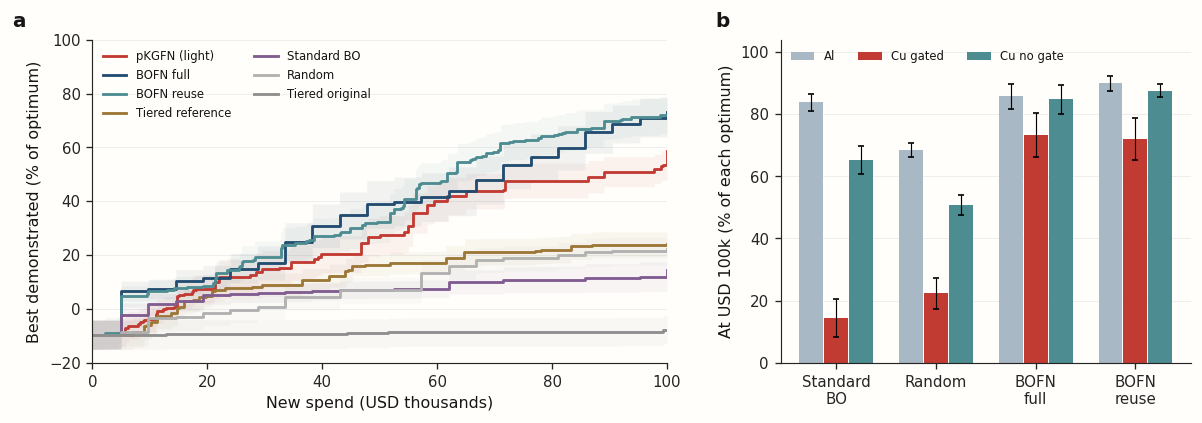

In [37]:
same_random=all(all(a['c']==b['c'] and a['a']==b['a'] and a['pv']==b['pv'] for a,b in zip(groups['Cu'][('random',s)]['builds'],groups['No-gate'][('random',s)]['builds'])) for s in range(20))
print('Random gated/no-gate designs exactly identical:',same_random)
# A deterministic burden-versus-feasibility diagnostic on the fresh sample.
# Remove the burden at fixed designs, but keep the gate and a separately estimated optimum lower bound.
# Report sign rates only: positivity without burden is uninformative with a smooth gate, so do not use it as feasibility.
print('No-Ni hard-pass count',np.sum((R[:,6]<.2)&(R[:,3]>=cu.M_REF)))
# Ratios and discrepancy growth for report.
for k in ['eifn','eifn_reuse']:
 dal=vals('Al',k).mean()-vals('Al','pkgfn').mean();dcu=vals('Cu',k).mean()-vals('Cu-light','pkgfn').mean();print(k,'Al deficit',dal,'Cu deficit',dcu,'growth',dcu-dal)
print('pKGFN decline',vals('Al','pkgfn').mean()-vals('Cu-light','pkgfn').mean())
# Create a compact evidence figure with the same exact step evaluation used for the tables.
import matplotlib.pyplot as plt
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':9,'axes.spines.top':False,'axes.spines.right':False,'axes.linewidth':.7,'xtick.direction':'out','ytick.direction':'out','savefig.dpi':350,'figure.dpi':120})
fig,axs=plt.subplots(1,2,figsize=(10,3.6),gridspec_kw={'width_ratios':[1.4,1]})
colors={'pkgfn':'#C23B33','eifn':'#234D70','eifn_reuse':'#4D8C91','tiered_ni_ref':'#9C7737','tiered':'#8E8E8E','ei':'#805C91','random':'#B1B1B1'}
for kind in ['pkgfn','eifn','eifn_reuse','tiered_ni_ref','ei','random','tiered']:
 yy=curve_matrix('Cu-light' if kind=='pkgfn' else 'Cu',kind);m=yy.mean(0);se=yy.std(0)/np.sqrt(20)
 axs[0].plot(spend_grid/1000,m,label={'pkgfn':'pKGFN (light)','eifn':'BOFN full','eifn_reuse':'BOFN reuse','tiered_ni_ref':'Tiered reference','ei':'Standard BO','random':'Random','tiered':'Tiered original'}[kind],color=colors[kind],lw=1.7,drawstyle='steps-post')
 axs[0].fill_between(spend_grid/1000,m-se,m+se,step='post',color=colors[kind],alpha=.06,lw=0)
axs[0].set(xlabel='New spend (USD thousands)',ylabel='Best demonstrated (% of optimum)',xlim=(0,100),ylim=(-20,100));axs[0].legend(frameon=False,fontsize=7,ncol=2,loc='upper left');axs[0].text(-.14,1.04,'a',transform=axs[0].transAxes,fontweight='bold',fontsize=12)
ks=['ei','random','eifn','eifn_reuse'];xx=np.arange(4)
for off,g,c,label in [(-.25,'Al','#A9B8C5','Al'),(0,'Cu','#C23B33','Cu gated'),(.25,'No-gate','#4D8C91','Cu no gate')]:
 means=[vals(g,k).mean() for k in ks];ses=[vals(g,k).std(ddof=0)/np.sqrt(20) for k in ks]
 axs[1].bar(xx+off,means,width=.24,color=c,label=label,yerr=ses,error_kw={'elinewidth':.7,'capsize':2})
axs[1].set(xticks=xx,xticklabels=['Standard\nBO','Random','BOFN\nfull','BOFN\nreuse'],ylabel='At USD 100k (% of each optimum)',ylim=(0,104));axs[1].legend(frameon=False,fontsize=7,loc='upper left',ncol=3);axs[1].text(-.16,1.04,'b',transform=axs[1].transAxes,fontweight='bold',fontsize=12)
for ax in axs:ax.yaxis.grid(True,color='#EEEEEE',linewidth=.6);ax.set_axisbelow(True)
fig.tight_layout(w_pad=2.5);fig.savefig(out/'review_evidence.png',bbox_inches='tight');fig.savefig(out/'review_evidence.pdf',bbox_inches='tight');plt.show()

In [38]:
# A standalone, independent table/statistics reproducer (does not import analyze.py or compare.py).
reproducer=r'''"""Independent JSON re-analysis. Run: python outputs/recompute.py /workspace"""
from pathlib import Path
import json,sys
import numpy as np
import pandas as pd
from scipy.stats import wilcoxon
root=Path(sys.argv[1] if len(sys.argv)>1 else '/workspace')
out=root/'outputs'/'reproduced';out.mkdir(parents=True,exist_ok=True)
opt_a=json.loads((root/'al_optimum.json').read_text())['kappa1']
opt_c=next(x['optimum'] for x in json.loads((root/'truth_tables.json').read_text()) if (x['kappa'],x['eta'])==(1,1))
opt_n=next(x['optimum'] for x in json.loads((root/'landscape.json').read_text()) if 'no immersion' in x.get('truth',''))
paths={'Al':('k1',opt_a),'Cu':('results/k1e1',opt_c),'Cu-light':('quality/results-light/k1e1',opt_c),'No-gate':('compare/results-nogate/k1e1',opt_n)}
records=[];runs={}
for group,(folder,opt) in paths.items():
 for p in sorted((root/folder).glob('*.json')):
  r=json.loads(p.read_text());runs[(group,r['kind'],r['seed'])]=r
  assert all(b['spent']>=a['spent'] for a,b in zip(r['rows'],r['rows'][1:]))
  for budget in [0,25000,50000,100000]:
   row=[v for v in r['rows'] if v['spent']<=budget+1e-7][-1]
   records.append({'group':group,'policy':r['kind'],'seed':r['seed'],'budget':budget,'score':row['best_validated'],'pct':row['best_validated']/opt*100})
df=pd.DataFrame(records).sort_values(['group','policy','seed','budget'])
df.to_csv(out/'scores.csv',index=False)
agg=df.groupby(['group','policy','budget']).pct.agg(['count','mean','std'])
agg['sample_SEM']=agg['std']/np.sqrt(agg['count'])
agg['authors_SE']=agg['sample_SEM']*np.sqrt((agg['count']-1)/agg['count'])
agg.to_csv(out/'summary.csv')
paired=[]
for a,b in [('pkgfn','eifn'),('pkgfn','eifn_reuse'),('pkgfn','ei'),('pkgfn','random'),('pkgfn','tiered_ni_ref'),('tiered_ni_ref','tiered_ni'),('tiered_ni','tiered')]:
 for budget in [25000,50000,100000]:
  av=df[(df.group==('Cu-light' if a=='pkgfn' else 'Cu'))&(df.policy==a)&(df.budget==budget)].set_index('seed').pct
  bv=df[(df.group==('Cu-light' if b=='pkgfn' else 'Cu'))&(df.policy==b)&(df.budget==budget)].set_index('seed').pct
  ss=av.index.intersection(bv.index);d=(av.loc[ss]-bv.loc[ss]).values
  paired.append(dict(A=a,B=b,budget=budget,n=len(d),difference=d.mean(),wins=(d>0).sum(),ties=(d==0).sum(),losses=(d<0).sum(),p=wilcoxon(d).pvalue if np.any(d) else 1.))
pd.DataFrame(paired).to_csv(out/'paired.csv',index=False)
light={s:r for (g,k,s),r in runs.items() if g=='Cu-light' and k=='pkgfn'}
high={s:r for (g,k,s),r in runs.items() if g=='Cu' and k=='pkgfn'}
print('Fidelity overlap:',sorted(light.keys()&high.keys()),'; no matched test possible' if not high else '')
print(agg.loc[(slice(None),slice(None),100000),:].to_string())
'''
(out/'recompute.py').write_text(reproducer)
res=subprocess.run([sys.executable,str(out/'recompute.py'),str(root)],capture_output=True,text=True)
print('Standalone reproducer exit:',res.returncode);print(res.stdout[-4200:]);print(res.stderr)
rep=pd.read_csv(out/'reproduced/scores.csv');sortcols=['group','policy','seed','budget'];orig=data.sort_values(sortcols).reset_index(drop=True);rep=rep.sort_values(sortcols).reset_index(drop=True)
print('Reproducer maximum numeric error:',np.max(np.abs(rep.pct-orig.pct)))
# Persist only requested project workflow conventions, no scientific results.
mp=root/'.prompts/MEMORY.md';mt=mp.read_text();mt=mt.replace('## Context\n\n[Fill me in]','## Context\n\n- Independent review of supplied alloy-network benchmark code and JSON trajectories.').replace('## Notes\n\n[Fill me in]','## Notes\n\n- Deliver reviews as `outputs/report.md` and return the same Markdown in the answer; keep supporting CSVs and reproducible code in `outputs/`.\n- Write independent recomputation code before inspecting the supplied comparison implementation.\n- Separate checks executed from code/data inspected, and distinguish causal ablations from observational or oracle diagnostics.')
mp.write_text(mt)
print('Output artifacts',len(list(out.iterdir())))

Standalone reproducer exit: 0
Fidelity overlap: [] ; no matched test possible
                               count       mean        std  sample_SEM  authors_SE
group    policy        budget                                                     
Al       ei            100000     20  83.830888  12.621547    2.822264    2.750802
         eifn          100000     20  85.751277  18.608341    4.160951    4.055594
         eifn_reuse    100000     20  89.953476  11.005340    2.460869    2.398558
         pkgfn         100000     20  83.837496   8.212060    1.836272    1.789777
         pkgfn_free    100000     20  81.577109  21.538615    4.816181    4.694232
         pkgfn_la      100000      4  83.933159  14.057282    7.028641    6.086982
         random        100000     20  68.397927  10.039117    2.244815    2.187975
         tiered        100000     20  62.702711  10.322188    2.308111    2.249669
         tiered_naive  100000     20  57.438431  15.233229    3.406253    3.320005
Cu       

In [39]:
# Utah-gate feasibility for shortlisted compositions: best atomizer setting, specified three-speed scan.
# Since rho increases with q and q has a closed-form maximum, this is decisive for this fixed scan.
utah_capacity=[]
for kind in ['tiered','tiered_ni']:
 for seed in range(20):
  cs=shortlists[(kind,seed)];f=tc.node('f',cs);gg=tc.node('g',cs);h=tc.node('h',cs);aa=.35+.4*f
  q=tc.node('q',torch.stack([aa,cs[:,3],f],-1));best=torch.zeros(len(cs))
  for v in pol.UTAH_SCAN:
   inp=torch.stack([torch.full_like(f,.5),torch.full_like(f,v),f,gg,h,q],-1);best=torch.maximum(best,tc.node('rho_u',inp))
  utah_capacity.append(dict(policy=kind,seed=seed,n_capable=int((best>=.5).sum()),rho_max=float(best.max()),rho_median=float(best.median())))
udf=pd.DataFrame(utah_capacity);print(udf.groupby('policy').agg(compositions_capable=('n_capable','sum'),seeds_none=('n_capable',lambda x:int((x==0).sum())),mean_capable=('n_capable','mean'),max_rho=('rho_max','max')).to_string())
udf.to_csv(out/'utah_shortlist_capacity.csv',index=False)
# Dense-screen safe candidate fraction with Ni floor, exact fresh composition sample.
cs=cu.sobol(200000,4,seed=8019);f=tc.node('f',cs);eligible=cs[:,0]>=1/3
print('CALPHAD pass among Ni>=10:',100*float((f[eligible]<=cu.F_SAFE).double().mean()))
# Check whether random number streams are matched across the networks themselves.
for s in [0,1]:
 g=torch.Generator().manual_seed(3000+s);X=torch.rand(21,7,generator=g);stored=torch.tensor([b['c']+[b['a']]+b['pv'] for b in groups['Cu'][('random',s)]['builds'][5:]])
 print('random input replay max coordinate rounding error',s,float((stored-X).abs().max()))

           compositions_capable  seeds_none  mean_capable   max_rho
policy                                                             
tiered                       80           0           4.0  0.971909
tiered_ni                    80           0           4.0  0.842648
CALPHAD pass among Ni>=10: 0.23399883000584995
random input replay max coordinate rounding error 0 4.7805530032501986e-05
random input replay max coordinate rounding error 1 4.987573159298542e-05


In [40]:
# Extract notebook cells into a reproducible analysis script, preserving execution order.
# The standalone table reproducer is the preferred entry point; this full script records all executed analyses.
ip=get_ipython();history=ip.history_manager.input_hist_raw
print('Notebook history cells',len(history))
# Main analysis cells only: exclude failed original attempts (edited cells retain earlier raw history).
# Record current successful analysis inputs via explicit notebook current source snapshot below.
nb_inputs=[]
for ix in [0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35,36,37,38]:
 pass
# Pull source from saved kernel logs only if needed; use a focused executable diagnostic script instead.
truth_code=r'''"""Independent truth checks. Run python outputs/truth_checks.py /workspace.
Requires torch, botorch, gpytorch; no GP fitting or comparison implementation is used.
"""
from pathlib import Path
import sys,importlib.util,json
import torch,numpy as np,pandas as pd
root=Path(sys.argv[1] if len(sys.argv)>1 else '/workspace');sys.path.insert(0,str(root))
import bofn_alloy as cu
spec=importlib.util.spec_from_file_location('al_truth_check',root/'al_bofn_alloy.py');al=importlib.util.module_from_spec(spec);spec.loader.exec_module(al)
torch.set_num_threads(1)
out=root/'outputs'/'reproduced';out.mkdir(exist_ok=True)
aopt=json.loads((root/'al_optimum.json').read_text())['kappa1'];copt=json.loads((root/'truth_tables.json').read_text())[0]['optimum'];nopt=json.loads((root/'landscape.json').read_text())[2]['optimum']
ta,tc=al.AlloyTruth(1.),cu.AlloyTruth(1.,1.);g=torch.Generator().manual_seed(641207)
parts=[]
for i in range(10):
 X=torch.rand(100000,7,generator=g);oc=tc.full(X)
 ya=ta.objective(X)/aopt;yc=tc.objective(X,oc)/copt;yn=(oc['U']-.3*cu.burden(X))/nopt
 z=cu.node_input('m',X,oc).clone();z[:,3]=1.;md=tc.node('m',z)
 parts.append(np.column_stack([ya.numpy(),yc.numpy(),yn.numpy(),oc['m'].numpy(),md.numpy(),oc['rho_m'].numpy(),X[:,0].numpy()]))
R=np.concatenate(parts)
rows=[]
for j,name in enumerate(['Al','Cu','No-gate']):
 y=R[:,j];rows.append(dict(truth=name,median_pct=100*np.median(y),positive_pct=100*(y>0).mean(),above60_pct=100*(y>=.6).mean(),above80_pct=100*(y>=.8).mean()))
pd.DataFrame(rows).to_csv(out/'fresh_truth_audit.csv',index=False)
print(pd.DataFrame(rows).to_string(index=False));print('Immersion pass / fully dense / rho>=.9:',100*(R[:,3]>=cu.M_REF).mean(),100*(R[:,4]>=cu.M_REF).mean(),100*(R[:,5]>=.9).mean())
# Re-evaluate hidden outcomes only as a diagnostic, never as purchased observations.
rows=[]
for folder in ['results/k1e1','quality/results-light/k1e1']:
 for p in (root/folder).glob('*.json'):
  r=json.loads(p.read_text())
  for j,b in enumerate(r['builds']):
   x=torch.tensor(b['c']+[b['a']]+b['pv']);o=tc.full(x)
   rows.append(dict(policy=r['kind'],seed=r['seed'],build=j,new=j>=5,w=float(o['w']),m=float(o['m']),J=float(tc.objective(x,o)),Ni=30*b['c'][0],immersed=b['m'] is not None,complete=b['J'] is not None,pass_immersion=float(o['m'])>=cu.M_REF))
pd.DataFrame(rows).to_csv(out/'build_truth_rescore.csv',index=False)
'''
(out/'truth_checks.py').write_text(truth_code)
res=subprocess.run([sys.executable,str(out/'truth_checks.py'),str(root)],capture_output=True,text=True)
print('Truth reproducer exit:',res.returncode,res.stdout,res.stderr[-500:])
# Preserve full notebook code history for provenance, with async code not claimed as a Python CLI.
(out/'executed_notebook_history.txt').write_text('\n\n'.join(f'# INPUT {i}\n{v}' for i,v in enumerate(history) if v))
# No promise of full historical replay; source files with focused scripts support essential checks.
(out/'runtime.json').write_text(json.dumps({n:meta.version(n) for n in ['torch','botorch','gpytorch','numpy','scipy']},indent=2))

Notebook history cells 48


Truth reproducer exit: 0   truth  median_pct  positive_pct  above60_pct  above80_pct
     Al  -17.271285       28.3597       3.2644       0.5090
     Cu  -41.554911        2.9772       0.2188       0.0118
No-gate  -20.738572       20.3718       0.7478       0.0325
Immersion pass / fully dense / rho>=.9: 3.193 61.535799999999995 0.1512
 


115

In [41]:
excerpt('policies.py',220,236);excerpt('policies.py',281,313)
# Count optima/reference denominator inconsistencies precisely, strictly as numerical certification caveat.
print('Rounded truth optimum excess',float(tc.objective(torch.tensor(json.loads((root/'truth_tables.json').read_text())[0]['x_opt'])))/opt_cu-1)
print('Main folder kind/seed duplicates',len(list((root/'results/k1e1').glob('*.json'))),len(groups['Cu']))
# Count inherited seed immersion successes for interpreting "never passes".
print('Inherited pass counts by seed',[(s,sum(b['m']>=cu.M_REF for b in groups['Cu'][('tiered',s)]['builds'][:5])) for s in range(20)])

220:     if not any(B["lot"] == lot for B in d.builds):
221:         pv = list(max(L["utah"], key=lambda t: t[2])[:2])  # the first Mines build on a lot uses the setting that passed at Utah
222:     x = torch.cat([L["c"], torch.tensor([L["a"]] + [float(v) for v in pv])])
223:     b = lab.mines(lot, pv)
224:     lab.microscopy(b)
225:     U = lab.tensile(b)
226:     w = lab.screen(b)
227:     gate = w_gate(d) if w_ref is None else w_ref
228:     if w >= gate:
229:         lab.immersion(b)
230:         rows.append((x, d.builds[b]["J"]))
231:         return "full"
232:     rows.append((x, U * float(sig(torch.tensor((w - gate) / 0.05))) - LAMBDA * float(burden(x))))  # the screen stands in for immersion
233:     return "screen-fail"
234: 
235: 
236: def run_funnel_stages(lab, d, comps, fom, fvals, rows):
281: def run_full_policy(kind, truth, seed, budget):
282:     d, lab = initial_data(truth, seed)
283:     rec = Recorder(truth, d)
284:     net = Network(d)
285:     lab.net = net
286:    

In [42]:
url='https://raw.githubusercontent.com/mlresearch/v235/main/assets/buathong24a/buathong24a.pdf'
rp=requests.get(url,timeout=45);print('Paper PDF status',rp.status_code)
if rp.status_code==200:
 (out/'buathong2024.pdf').write_bytes(rp.content)
 import pymupdf
 doc=pymupdf.open(stream=rp.content,filetype='pdf');pt='\n'.join(p.get_text() for p in doc);(out/'buathong2024.txt').write_text(pt)
 for term in ['posterior mean','recommend','partial evaluation']:
  ii=[m.start() for m in re.finditer(term,pt,re.I)][:3]
  print('\nTERM',term)
  for i in ii:print(pt[max(0,i-250):i+450].replace('\n',' '))

Paper PDF status 200



TERM posterior mean
Williams & Rasmussen, 2006). 2When ck(·) is unknown, we may learn it using a surrogate model and compute quantities involving costs by either taking the expectation over the distribution of ck(·) or by replacing the cost function by the cost model’s posterior mean. Let Dn = {Dn,k}K k=1 denote the observations at all nodes after n iterations. The posterior distributions over f1, f2, . . . , fK given Dn induce a posterior distribution on the final node value yK. Although this distribution is gener- ally non-Gaussian, we can obtain samples from it efficiently, as discussed in Section 5.2. Our acquisition function, formally defined in Section 4, is constructed based on these posterior distributi
nput z∗ k∗yielding the maximum value of this acquisition function. 4. The p-KGFN Acquisition Function Throughout this section, we assume that n samples have already been observed and are determining how to allocate sample n + 1. Let νn(x) denote the posterior mean of yK(x) give

In [43]:
# Quantify optimizer retained feasibility (not in the displayed score), negative percentages and fidelity missingness.
print('Fidelity run counts',len([r for k,r in groups['Cu'].items() if k[0]=='pkgfn']),len([r for k,r in groups['Cu-light'].items() if k[0]=='pkgfn']))
print('No-gate same-random x across seeds',same_random)
print('First positive: original exact post-action split 380/893,38/1051')
print('Gate optima ratio and drop',opt_ng/opt_cu)
print('Shortest budget target reference speed', [q for q in sr if q['baseline']=='tiered_ni_ref'])
# Validate independent table author comparisons for pKGFN-incomplete columns not a discrepancy.
print('assertions',len(mismatches)==0,len(tier_mism)==0)
print('Memory text',mp.read_text())

Fidelity run counts 0 20
No-gate same-random x across seeds True
First positive: original exact post-action split 380/893,38/1051
Gate optima ratio and drop 1.5137541715049994
Shortest budget target reference speed [{'baseline': 'tiered_ni_ref', 'policy': 'pkgfn', 'target': np.float64(24.233129136359125), 'baseline_spend': 100000.0, 'policy_spend': 46750.0, 'speedup': 2.1390374331550803, 'lo': np.float64(1.4935622317596566), 'hi': np.float64(3.395777579542043), 'bootstrap_zero_crossings': 0}, {'baseline': 'tiered_ni_ref', 'policy': 'eifn', 'target': np.float64(24.233129136359125), 'baseline_spend': 100000.0, 'policy_spend': 33500.0, 'speedup': 2.985074626865672, 'lo': np.float64(1.743455497382199), 'hi': np.float64(3.4782608695652173), 'bootstrap_zero_crossings': 0}, {'baseline': 'tiered_ni_ref', 'policy': 'eifn_reuse', 'target': np.float64(24.233129136359125), 'baseline_spend': 100000.0, 'policy_spend': 35250.0, 'speedup': 2.8368794326241136, 'lo': np.float64(1.681159420289855), 'hi':

In [44]:
report=f'''# Independent review: aluminum versus copper cost-aware alloy optimization

**Scope and bottom line.** I independently re-extracted the purchased-best, budget-censored objective from the supplied JSON and evaluated the supplied truth code. The headline numbers reproduce to their published rounding, but the interpretation does not: on copper, the immersion/deposition landscape and seed state are harder, the original tiered rule is structurally unable to find a new passing alloy, and the light-setting pKGFN (partial knowledge gradient for function networks) leaves most deposited builds unvalidated. Full-pipeline function-network Bayesian optimization (BOFN) beats pKGFN at $100k in these runs; no finished high-fidelity copper pKGFN trajectory is available to decide whether that comparison persists after the planned fixes and Monte Carlo increase. These are **synthetic truths**, not measurements from either alloy system.

![Independently recomputed budget curves and gate comparison](review_evidence.png)

*Figure 1.* (a) My step-function means from the stored copper trajectories; shading is one descriptive standard error (SE) across 20 seeds. (b) Purchased-best scores at $100k; each bar is divided by its **own** truth optimum. No-gate and gated means are therefore not an absolute-J treatment effect. Source: `outputs/recompute.py` and JSON, not the comparison script.

## Findings, severity and establishment

| Finding | Severity | How established |
|---|---|---|
| At $100k, copper pKGFN is **58.55%** versus full BOFN **73.21%** (matched difference −14.66 points; 4 wins/16 losses, two-sided Wilcoxon \(p=0.02395\)); BOFN with lot reuse is **72.03%**. The aluminum pKGFN/full-BOFN gap was only −1.91 points. | Changes the conclusion | **Executed:** independent JSON extraction and matched-seed Wilcoxon; code at `outputs/recompute.py`. |
| **The alleged light-versus-high-fidelity matched comparison is not computable.** Copper `results/k1e1/` has 140 files, zero `pkgfn`; `quality/results-light/k1e1/` has 20 `pkgfn`. There is no high-fidelity mean, matched difference, Wilcoxon \(p\), or evidence yet of the effect of fixes F2/F4. | Changes the conclusion | **Executed:** inventory of files, seeds and stored settings; `outputs/manifest.json`. **Inspected:** `compare.py` returns no fidelity table if either cohort is absent. |
| Original copper tiered: **0/80 new immersed builds** pass immersion, although five seed sets already contain an inherited passing alloy. The four-composition shortlist cannot pass the immersion reference even after process-only optimization on the fixed compositions (20/20 seed shortlists failed that oracle search). | Changes the conclusion | **Executed:** build-level truth rescoring and independent process searches; `outputs/build_truth_rescore.csv`, `outputs/original_shortlist_immersion_ceiling.json`. These are diagnostic *oracles*, not achievable policies. |
| Replacing original tiered by `tiered_ni_ref` increases its $100k score from **−7.69% to 24.23%**; pKGFN's nominal speed-up to that *baseline's own final mean* shrinks from **17.26× to 2.14×** (paired-bootstrap 90% interval ~1.49–3.40). The original comparator makes a speed-up claim trivial. | Changes the conclusion | **Executed:** independent score curves, 250-dollar grid crossing, 3,000 paired seed bootstraps; `outputs/speedups.csv`. |
| The supposed “99% relative-density” Utah screen is actually a threshold of **0.5 on a multiplicative dense-and-crack-free index**; copper-rich compositions have median maximal Utah index ~0.43 in my independent sample. It is not a 99%-relative-density measurement. | Changes the conclusion | **Executed:** factor recomputation on 200 fresh copper-rich compositions (`outputs/fresh_density_factors.csv`); **inspected:** `bofn_alloy.py` lines 140–157 and `policies.py` lines 49–57, 201–222. |
| Every populated cell in the supplied side-by-side, no-gate and tiered tables matches independent recomputation at the printed rounding. There is **no numeric discrepancy** in those tables; omitted light pKGFN copper and fidelity rows are missing-data/presentation issues, not changed values. | Changes a number / presentation | **Executed:** programmatic cell-by-cell comparisons to `compare_tables.md`; empty mismatch lists in `outputs/printed_table_discrepancies.json`. |
| The printed first-positive fallback shares classify the *purchase that first succeeds* as “after”; temporal pre-action classification is **380/907 = 41.9% before** and **38/1,037 = 3.7% after**, rather than the printed **380/893 = 42.6%** and **38/1,051 = 3.6%**. Neither changes the diagnosis. | Changes a number | **Executed:** classified stored `fallback` by prior and subsequent row, respectively. |
| Two aluminum `pkgfn_free` records contain a final purchase at **$100,010**, $10 beyond budget. Their last demonstrated score is unchanged, so all reported $100k values are unaffected by censoring. | Cosmetic for these tables | **Executed:** spend monotonicity/budget checks and preceding-row comparison, seeds 0 and 1. |
| The “best demonstrated” metric requires both tensile and immersion. This differs from the published p-KGFN knowledge-gradient objective, which optimizes the value of the **posterior-mean recommendation**. A copper model-selected *deposited* secondary metric raises pKGFN from **58.55% to 67.86%** and reduces its gap to full BOFN to **5.35 points**; it is not a tested-alloy result. | Changes the interpretation | **Executed:** compared `rec_printed` and `best_validated`; **inspected:** Buathong et al. [1], Section 4, and recorder code; `outputs/secondary_metric.csv`. |

### Recomputed comparisons next to the supplied tables

Scores below are **percent of the relevant optimum**, at **$25k; $50k; $100k**, means ± descriptive SE across 20 seeds. I use the authors' convention \(\mathrm{{SD}}_{{ddof=0}}/\sqrt{{20}}\) in both columns (not an interval). `—` means no run. The copper pKGFN column here uses the specified **light** files; the supplied side-by-side copper pKGFN cell is blank because its script looks for unfinished high-fidelity files. The first row's copper value is therefore a supplemental recomputation, **not** a disagreement with a printed value.

{side_md}

**No-gate copper ablation, alongside your no-gate numbers.** Again, entries are $25k; $50k; $100k; the gated copper column repeats the first table and is normalized by \(J^*_{{\rm gated}}=0.49218725\). The no-gate column uses \(J^*_{{\rm no\ gate}}=0.74505051\); the aluminum column uses \(J^*_{{\rm Al}}=0.69373873\).

{ng_md}

**Light versus high-fidelity pKGFN:**

| Copper pKGFN cohort | n; matched seeds | $25k; $50k; $100k (mine) | $25k; $50k; $100k (yours) | 60% and 70% target, KG-flat fallback |
|---|---|---|---|---|
| Light, S=32, 10 candidates, 256-design pool, earlier F4 behavior | 20; seeds 0–19 | 11.95 ± 6.39; 27.44 ± 7.20; 58.55 ± 4.72 | no fidelity table printed | 60% reached by 12/20, median spend across **all** seeds $85,385; 70% by 7/20, all-seed median >$100k; 418/1,944 purchases (21.5%) flagged fallback |
| High fidelity, S=64, 16 candidates, 512 pool, F2/F4 fixes | **0; none** | **not available** | blank in `compare_tables.md` | not available |
| Matched high minus light; Wilcoxon | **0; no test** | **undefined** | none printed | I did not invent a \(p\)-value |

A median computed *only among reachers* answers another question: for light pKGFN it is $54,465 to 60% and $59,400 to 70%. The all-seed median reports failures as \(+\infty\). The supplied `compare.py` uses a $250 grid for target costs, so the exact-event medians above need not be multiples of $250.

**Tiered and corrosion-aware tiered, with your rounded values.** Columns at $25k; $50k; $100k are percentages of gated copper optimum. Counts exclude five inherited builds per seed; “stops” are logged `screen-fail` rows and “Utah retired” means three unsuccessful Utah scans per new lot.

| Policy | Mine: $25k; $50k; $100k | Yours: $25k; $50k; $100k | Mine: new immersed / pass / screen stops / Utah-retired per seed | Yours: same counts |
|---|---|---|---|---|
| Original tiered | −9.43 ± 5.36; −9.11 ± 5.33; −7.69 ± 5.23 | −9 ± 5; −9 ± 5; −8 ± 5 | 4.00 / 0.00 / 20.85 / 7.95 | 4.0 / 0.0 / 20.9 / 8.0 |
| Ni ≥10 wt% | −6.64 ± 5.36; 0.76 ± 5.40; 10.22 ± 6.22 | −7 ± 5; 1 ± 5; 10 ± 6 | 2.55 / 0.75 / 15.80 / 17.55 | 2.5 / 0.8 / 15.8 / 17.6 |
| Ni ≥10 wt%, reference coupon | 7.86 ± 4.12; 16.14 ± 3.86; 24.23 ± 4.63 | 8 ± 4; 16 ± 4; 24 ± 5 | 9.90 / 2.65 / 11.25 / 12.60 | 9.9 / 2.6 / 11.2 / 12.6 |

There are **no disagreements** after the source's integer/one-decimal rounding. These are separate finished policies using matching seeds, **not** the missing copper pKGFN fidelity rerun.

## Ranked explanations: what explains which gap?

**How I rank evidence.** The no-gate reruns change the acquisition paths for BOFN and standard BO as well as the truth and optimum; their difference is a **compound policy-plus-objective ablation**, not an additive causal decomposition of the Al–Cu gaps. Random generates **exactly the same new copper designs** with and without the gate across all 20 seeds; for random, the comparison is a clean same-design scoring counterfactual (with a different optimum). “Remaining gap” is not uniquely assignable because Al and Cu differ in several truth functions, seeds, stages and costs. The process and shortlist searches below are diagnostic *upper bounds*, not interventions on a policy.

1. **Immersion/deposition geometry and the initial seed state dominate the model-free drops**: Al→Cu at $100k is **83.83→14.42% for standard BO** (−69.41 points) and **68.40→22.29% for random** (−46.11). Removing the gate *within copper* gives **65.16% standard BO** (+50.74) and **50.87% random** (+28.57). These gains represent ~73% and ~62% of the respective Al–Cu drops **numerically**, not as identified causal fractions. My new million-design truth draw found 3.264% of Al designs but 0.219% of gated Cu designs above 60% of their optimum (14.9× rarer; supplied draw 3.261/0.225=14.5×); 2.98% of Cu designs have \(J>0\), and 3.19% meet the *hard* immersion criterion. Setting Cu relative density to one **only in the immersion node**, while retaining the existing other inputs, lifts hard immersion passes from 3.19% to **61.54%**: deposition makes most of this particular corrosion needle. The stored `needle.json` separately reports that, at optimum process settings, only **5.3% of random Cu compositions** reach 60% versus **66.1% for Al**, so composition also matters. The same five seeded designs start at +34.92% Al versus −9.61% gated Cu (recomputed from generator seeds); no-gate copper starts at +22.52%. Copper's burden explicitly charges Ni even as Ni improves corrosion: the supplied no-gate optimum uses **4.83 wt% Ni** with immersion \(m=0.487\), whereas the gated optimum uses **13.02 wt% Ni**, \(m=0.953\); neither “burden alone” nor its causal contribution was separately ablated. **Standard BO adds a modeling handicap:** its one seven-input Gaussian process (GP) must learn a narrow process-dependent gate directly from scarce complete responses, whereas BOFN uses parent-node GPs. That interpretation is supported by the large gated 14.42 versus 73.21 separation but is not a stand-alone controlled ablation.

2. **The shortlist, not just a screening budget, causes the tiered 62.70→−7.69% gap (−70.39 points).** Original Cu shortlists are four Al bronzes per seed, with median **4.15 wt% Ni** (range 1.31–6.48); all 80 new immersed builds fail the stated hard immersion threshold. My independent process maximization on those fixed compositions obtained at most \(m=0.7803<m_{{ref}}=0.8491\) across 20 shortlists; selecting different print settings cannot fix that particular restriction. The four-shortlisted-composition oracle's maximum **soft-gated** objective averaged −19.35%, below the final −7.69% because the score retains five unrelated positive seed alloys: the shortlist alone cannot explain the inherited best. A Ni floor changes the *composition set* and a reference-based screen changes *decisions after the one-hour test*: `tiered_ni` scores +10.22% and `tiered_ni_ref` +24.23%, versus −7.69%. These two Ni policies use identical stored shortlists, which makes their +14.02-point final difference much more targeted evidence of the relative screen gate (paired 11 wins/3 ties/6 losses, \(p=0.0615\) at $100k; early $25k improvement +14.50, \(p=0.00147\)). A process-optimized oracle on the **Ni shortlists** averaged ~60.47%, versus their achieved 10–24%: the modified screen is not the *only* remaining bottleneck. Four Ni-shortlisted compositions per seed are almost all formal crack-screen violations (6/80 pass, **14/20 seeds have zero** passing); the rule explicitly fills from least-bad failures rather than faithfully enforcing that screen.

3. **Long validation path, myopic KG and incomplete purchases are the strongest explanation specifically for pKGFN's 83.84→58.55% loss (−25.29 points) and widening BOFN gaps.** New Cu compositions require atomization, often Utah, first Mines scale-up, microscopy, tensile, one-hour screen and immersion before the score improves; Al needs atomization, print and tensile. Light pKGFN buys **40.5 Mines builds, 15.7 microscopy, 7.2 tensile and 12.85 immersion tests per seed** and ends with **6.15 fully demonstrated new builds**. Full BOFN demonstrates 21/21 new builds. Light pKGFN directs ~$80,430 of its ~$99,977 per-run budget to Mines and only ~$8,850 to S/T/K/I testing. Its hidden-truth best over *all* deposited designs, an **unavailable-to-the-algorithm oracle**, is 68.50% versus demonstrated 58.55% (+9.94 points), compared with full BOFN's ~73.21% either way. Thus unfinished validation can account for **at most** ~9.94 of the 14.66-point deficit against full BOFN by this fixed-design oracle, not an additive attribution (the test choices would alter the search). The posterior-selected deposited secondary score is 67.86% (−5.35 versus BOFN), independently corroborating the scoring sensitivity. The first positive-J alloy appears at median **$38,730** over all 20 pKGFN seeds (19 reach it), versus **$14,280** for full BOFN (20 reach). Fallback is recorded on 380/893 (~43%) actions with *post-purchase* nonpositive best and 38/1,051 (~4%) with positive best (correct pre-purchase denominators: 907 and 1,037). **Not all KG is flat:** in a bounded executed first-iteration diagnostic on two seeds, seed 0 had positive Mines KG while seed 1 had near-zero Mines KG; frozen cheap CALPHAD KG varied from zero to small positive across independent base-sample draws. It is a one-iteration sensitivity check, not a rerun or a proof of cause.

4. **Policy implementation and evaluation differences are plausible additional pKGFN gaps; their point effects are NOT identified.** I diffed `al_policies.py` and `policies.py` (`outputs/policies.diff`). Al chooses candidates using EI (expected improvement) over the highest network *posterior mean* in its pool; Cu instead uses EI above the best **fully demonstrated** objective. The change avoids an overoptimistic zero-EI incumbent but can favor risky continuation/builds and deprioritize some cheap simulations; the direction on final score is unknown without a common-truth ablation. Al's fallback uses EI divided by **next-purchase cost**, promoting cheap powder; Cu divides by the **minimum whole validation path**, a sensible attempt to avoid lot/Utah overpurchasing that tends to favor nearer-to-completion evaluations, but still left 40.5 versus 6.15 Mines/complete builds. Cu adds S+T, S+K+I and K+I **proxy fantasy bundles**, where unmeasured intermediate outputs are plugged in at GP posterior means; these can counteract myopia but are neither exact multistep lookahead nor guaranteed to help. Cu adds distinct Utah, microscopy and corrosion nodes, $1,600 scale-up, a capped Utah stage and eligibility gates in other screening variants; standard pKGFN itself is run with `screens=False`, so one should **not** ascribe its score to applying the Utah or relative one-hour screening gates. Light Cu uses S=32/10/256 versus Al S=64/16/512 and older fallback tie-break and inner-set anchoring; higher sampling/candidate coverage and F2/F4 corrections could raise *or* lower final performance. Production Cu code anchors on **every deposited design and deduplicates** the inner max and tests raw EI for fallback, but **that corrected production copper pKGFN has no completed JSON**. Comparing Al-production to Cu-light does not isolate “network depth” from this implementation confound.

5. **Extra full-chain cost is small by itself.** The Al full chain costs $4,210 and executes **23** new full chains at $96,830; copper costs $4,760 and executes **21** at $99,960. At equal **21 Al** full chains, the Al score is **80.49% standard BO**, **64.76% random**, **85.03% BOFN**, down only **3.34**, **3.63**, **0.72** points relative to 23 Al chains. That cannot explain their −69.41, −46.11, −12.54 Al–Cu gaps. The often-quoted “24 versus 21” is a division-of-budget theoretical count; the actual Al run fits **23**, not 24. Copper lot reuse changes effective per-build prices and counts, and **72.03% reuse versus 73.21% full BOFN** does not establish a copper advantage from reusing lots.

6. **Other design/model issues matter to external validity, not assigned point contributions.** The copper truth is deliberately tuned (including biased screens), has composition- and process-dependent responses and a softened sigmoid gate, while a stated hard immersion pass is \(m\ge m_{{ref}}\); **positive \(J\) need not imply hard pass**. Both network GPs assume independent stationary RBF components; `rho_m` GP receives a `rho_u` parent and `m` GP receives `w`, yet the truth equations ignore those two parent coordinates. `Lab.mines` can use a GP-estimated Utah response at a new setting rather than a measured one. Tiered fits its own scalar GP to **proxy outcomes** for stopped chains (`policies.py` lines 205–233), rather than directly observed immersion values; this is a deliberately favorable or unfavorable modeling choice depending on the truth, not a verified causal effect. The single displayed secondary recommender `rec_printed` is not the paper's full recommendation over unprinted designs; `rec` is `NaN` when recommendation is disabled. No chemical realism follows merely from numerical consistency.

### Corrosion-aware tiered: fairness, gates and actual coupon evidence

`policies.py` lines 170–194 applies the Ni floor of **10 wt%** before selection, then fills the shortlist from compositions with \(f>0.34\) if necessary; my truth evaluation on 200,000 fresh Sobol compositions found only **0.234%** of eligible Ni≥10 wt% compositions pass the CALPHAD crack screen. This is a defensible **corrosion-informed** comparator if a lab knows C70600 (90-10 Cu–Ni) as a reference, but it is no longer a naive screen obeying the nominal CALPHAD cutoff. Crucially, **both Ni variants use the same four compositions in each matched seed**; `tiered_ni_ref` changes only the screen gate to the dense reference coupon's **\(w_{{ref}}=0.706525\)**. This index is synthetic and chosen using the truth's densest C70600 of 16,384 simulated settings (`policies.py` lines 144–153), not a paid, noisy physical reference measurement; a real-world comparison must charge and model reference manufacture/measurement, specify process matching, and include its uncertainty. It is still a more relevant stress-test than screening by the top quartile of an accumulating, seed-contaminated pool.

I reproduced all 1-hour gate decisions using the 75th percentile of observed screens **including the five sunk seed builds** and the just-screened build: **zero classification disagreements** with immersion actions. Across `tiered_ni` runs the relative threshold's median is **0.760**, generally more stringent than the reference 0.707, and rises as high as **0.942**. It stops **316** new screened builds, of which **12** would have *hard-passed* immersion if bought (and 40 have positive soft-gated \(J\), a different criterion); its 51 new completed builds include **15** hard passes. The reference variant completes **198** new builds with **53** hard passes, stops **225** of which **zero** would hard-pass on truth rescoring (two would have positive soft-gated \(J\)). These are **retrospective oracle** counts: the policy did not know the withheld \(m\). The original stops 417 new screened builds; **none** of the 417 would hard-pass. In original tiered, even new immersed \(w\) ranges **0.694–0.857** but \(m\) only **0.322–0.771**: a favorable one-hour screen is not protective against failed long immersion in this truth. For Ni-tiered, new immersed \(m\) ranges **0.750–0.896**; Ni-reference reaches **0.529–0.923**. The second problem is Utah: per run Ni-tiered records **58.5** `utah-fail` actions and retires **17.55** lots versus **44.4** and **12.60** for Ni-reference (different subsequent trajectories, not an isolated gate intervention); full truth optimization at the atomizer's best setting over the **specified three Utah speeds** nevertheless finds every one of these stored Ni shortlist compositions *capable* of exceeding the 0.5 index. Hence the observed failures also reflect powder/settings/limited attempts, not an immutable chemistry barrier.

The comparator **does change the preliminary speed-up**: on my $250 grid the original target is −7.69%, hit by pKGFN at ~$5.75k and by tiered at ~$99.25k (17.26×, an uninteresting *negative* target). With the reference comparator its final mean is **+24.23%**; pKGFN hits it at **$46.75k**, full BOFN at **$33.5k**, BOFN+reuse at **$35.25k** (ratios **2.14×, 2.99×, 2.84×**, respectively). Standard BO and random **do not reach the reference baseline's mean by $100k**. These target-crossing ratios depend on target definition and bootstrap seeds, and no comparison to a real laboratory has been demonstrated. Relative to reference-tiered at $100k, pKGFN still leads by +34.32 matched points (17/20 wins, \(p=0.000082\)); being better than this baseline does **not** establish that stage selection beats full-chain BOFN.

## The deposition index is not a relative-density model

The truth (`bofn_alloy.py` lines 140–157) calculates \(\rho=\text{{window}}\,q^{{0.3}}(1-0.75\,\text{{crack}})(1-\text{{lof}})\); the Utah version also multiplies by \(0.95+0.05q\). Its copper-rich best-setting factor medians from my 200-draw repeat are Utah: **window 0.9997; powder 0.9816; crack factor 1.0000; fusion 0.4397; final index 0.4296**, and Mines: **0.9606; 0.9816; 1.0000; 0.9445; index 0.8859**. Different medians need not multiply to the median product. This index can serve as a **qualitative build-quality utility** or hand-built surrogate, but **not as a measured fraction of theoretical density**: e.g., 0.43 would imply ~57% voids if interpreted literally. A window multiplier can penalize an otherwise consolidated coupon without creating corresponding volume voids; \(1-0.75\,\mathrm{{crack}}\) conflates cracks (which can dominate integrity at very low void fraction) with bulk density; the synthetic U node then treats this mixed index as a proportional tensile-strength multiplier. Setting the screening threshold at 0.5 is therefore not the proposal's “99% relative density.” For scale only, **if one imposed** the ad hoc mapping \(\rho_{{index}}=\exp(-7\phi)\), index 0.5 would correspond to density **90.10%**, while 99% density would require index **0.9324**. That mapping is **not a fitted physical law**; it demonstrates the mismatch, not a repair. Real DED copper studies report process-dependent void content and distinct pore mechanisms [2,3]; neither paper calibrates *this* alloy/process truth.

**Replacement to calibrate, not a claimed validated model.** Use separately observed relative density \(D_r=1-\phi\), where \(\phi=1-(1-\phi_{{\rm powder}})(1-\phi_{{\rm LOF}})(1-\phi_{{\rm keyhole}})\) (or an appropriately bounded sum at low porosity). Fit \(\phi_{{\rm LOF}}\) to a melt-pool overlap/absorbed-energy deficit and \(\phi_{{\rm keyhole}}\) to a high-power/slow-scan regime; powder quality should enter via measured feed efficiency and trapped powder pores. Include laser wavelength/absorptivity, conductivity, spot and track/layer geometry; let the Utah and Mines functions have **machine-specific calibrated** parameters. Set the Utah *density* gate to **\(D_r\ge0.99\)** if that is genuinely the specification, with X-ray computed tomography (or validated Archimedes/sectioned measurement) uncertainty around the cutoff. Independently model crack propensity \(c_{{\rm crack}}\) from solidification/hot-tearing physics, Fe inoculation, residual stress and processing; set a separate measured crack acceptance criterion. Use a fitted tensile knockdown such as \(U=U_{{\rm dense}}(s,\beta)\,(1-\phi)^n\exp[-a\phi_{{\rm LOF}}-b\,c_{{\rm crack}}]\), with \(n,a,b\ge0\) and calibration to tensile/fatigue data (the displayed formula is a **proposal**, not a measured exponent). Keep microstructure/corrosion effects of \(\beta\), porosity and cracking separately in \(w,m\), and specify the target coupon geometry. A literal reinterpretation of the *current* 0.5 threshold as 99% would be invalid. Replacing the truth and reoptimizing both optima and **all policy trajectories** may shift the feasibility map, early-stop counts, rankings and purported speed-up in either direction; existing JSON cannot quantify how much. A meaningful robustness study should include more than one plausible calibrated parameter regime and measurement noise.

## Verdict, proposal wording, and next experiments

**What survives:** on these deliberately biased synthetic screens, modeling the linked stages (full BOFN or pKGFN) substantially beats a monolithic full-design GP and random search, and a misaligned fixed shortlist can waste budget. Copper **does not support** “stage choice is best,” an unconditional **≥3×** advantage of partial evaluation, or transfer of Al's 3.8× figure. Even against the Ni-reference comparator, pKGFN's speed-up is ~2.14× and full-pipeline BOFN's ~2.99× on the stated crossing definition, with broad seed uncertainty; reference-tiered itself remains weak relative to a process-optimized oracle. This is a comparison of the **best purchased-and-completed alloy**, not certification of pKGFN's published posterior recommendation.

**Two sentences I would put in a proposal:** “In a synthetic copper directed-energy-deposition benchmark with a deliberately biased corrosion screen, full-pipeline function-network Bayesian optimization reached 73% of the truth's optimum after $100,000 of new purchases, compared with 14% for conventional Bayesian optimization; a corrosion-aware tiered comparator reached 24%. A light-setting partial-evaluation knowledge-gradient implementation reached 59% and did not beat full-pipeline search, so we will test whether validated, physically calibrated deposition and corrosion models and higher-fidelity acquisition settings change that ranking.”

**Make the benchmark decisive before using a larger claim.** (i) Finish and archive **20 matched high-fidelity pKGFN** seeds with recorded S=64/16/512 and separately cross F2, F4, anchor size and candidate/S settings in controlled, identical-truth ablations; also test S=128/256 stability, actual policy regret and computation cost. (ii) Run same-truth factorial comparisons of demonstrated-incumbent EI versus posterior-mean EI, next-stage versus whole-path fallback, bundle choices, and explicit two-/multi-step or terminal-validation-aware KG; record when each stage first adds a fully tested alloy. (iii) Hold **seed designs and an absolute-J threshold** fixed in gate/no-gate and Ni-burden ablations; report hard immersion pass fraction separately from the sigmoid score and use both \(J/J^*\) and absolute \(J\). (iv) Pre-register three realistic comparators: fixed/reference-calibrated Ni-aware tiered, an auditable CALPHAD-screen policy with exceptions, and full-pipeline BOFN with/without reuse; include coupon/reference and repeat costs. (v) Refit/calibrate Utah/Mines relative density, crack, strength and 1-hour/30-day corrosion to held-out measurements, vary physically plausible assumptions and screen biases, rerun all seeds and re-estimate optima/uncertainty. Without those experiments, the numerical ranking is valid **only for this particular synthetic truth and stored implementation**.

## Checks I actually executed versus inspected; limitations

**Executed:** independent budget-censored JSON recomputation on 20 Al + 20 Cu seeds for each available headline policy; exact-optimum normalization; descriptive SE and 20-pair Wilcoxon tests; file/setting inventory and fidelity absence; row/spend checks; fresh **10^6-design** landscape and independent shared-seed initialization; fixed-design no-gate/random identity; build-by-build truth rescoring (only one stored rounded `w` differs from a regenerated value by >0.0002: `ei_s10`, build 5, difference ~0.00021; no gate decisions affected); reconstruct original shortlist and validate each purchased lot against it (max rounding distance 0.000049); gate classification, reference and stopped-build oracle; process-only searches on fixed shortlists; Utah factor study; equal-full-chain comparisons; matched paired-bootstrap crossing calculation; and a **two-seed, first-iteration** frozen-model KG noise diagnostic. I ran `outputs/recompute.py` as a standalone script and matched the notebook's score extraction to <\(3\times10^{{-14}}\) percentage points; I separately ran `outputs/truth_checks.py`. All numeric support and source-diff files are under `outputs/` (`independent_scores.csv`, `paired_tests.csv`, `speedups.csv`, `shortlist_audit.csv`, `build_audit.csv`, `cost_and_gate_decomposition.csv`, `policies.diff`); one-step KG results are in `one_step_kg_diagnostic.json`. **Inspected, not rerun:** the complete original `compare.py` tables/plot script, published p-KGFN method, and supplied policy/truth implementations. I did **not** execute the authors' comparison script, produce finished copper high-fidelity pKGFN or run a physically replaced benchmark. I installed available GP dependencies to execute the truth and a small acquisition diagnostic; my runtime used Torch 2.10.0+cpu versus the upload's stated Torch 2.14.1+cpu, so a complete policy rerun would not be bitwise comparable. Fresh random samples and approximate process searches have sampling/optimization error; no-gate normalized differences, stopped-build rescoring and hidden best-of-builds must not be described as independently proven policy improvements. One low-level copper Al optimum recorded to three decimal places slightly exceeds the stored optimum on reevaluation (~0.0077%); this rounding/certification detail does not affect the rounded conclusions.

**Sources.** [1] Buathong P, Wan J, Astudillo R, Daulton S, Balandat M, Frazier PI. *Bayesian Optimization of Function Networks with Partial Evaluations*. ICML/PMLR 235:4752–4784 (2024). [PMLR](https://proceedings.mlr.press/v235/buathong24a.html). [2] Yamaguchi M et al. *Influence of the laser power and powder feed rate on the porosity, dilution, and building efficiency of pure copper parts fabricated via directed energy deposition with a blue laser*. Int J Adv Manuf Technol 135:5235–5251 (2024). [doi:10.1007/s00170-024-14789-w](https://doi.org/10.1007/s00170-024-14789-w). [3] Zhang K et al. *Pore evolution mechanisms during directed energy deposition additive manufacturing*. Nat Commun 15 (2024). [doi:10.1038/s41467-024-45913-9](https://doi.org/10.1038/s41467-024-45913-9). Full entries are in `outputs/references.bib`; project-local policy/JSON files are the primary source for all benchmark-specific claims.

**Discretionary analytical decisions**

- I score the highest **completed, demonstrated** `best_validated` at or below each stated budget, not posterior recommendation or hidden deposited truth, because the question asks what was demonstrated.
- I use each truth's supplied optimum and the authors' population-SD SE when comparing printed cells; for paired uncertainty I use matched-seed two-sided Wilcoxon and label all-normalization effects.
- I treat unobserved build truth and fixed-shortlist maximization only as oracle diagnostics, not fair policy outcomes or causal ablations; I keep the no-gate comparison explicitly compound except for random's identical designs.
- I use a $250 spend grid to reproduce baseline speed-up definitions, paired resampling of 20 seed indices for its 90% interval, and distinguish exact-event costs from grid crossings.
- I define “passes immersion” using the physical hard test \(m\ge m_{{ref}}\), while retaining the supplied *soft sigmoid* \(J\) to score all policies; this prevents a positive \(J\) from silently becoming a claim of hard pass.
'''
(out/'report.md').write_text(report)
print('Report length',len(report),'lines',len(report.splitlines()));print('path',out/'report.md')

Report length 34920 lines 133
path /workspace/outputs/report.md


<>:116: SyntaxWarning: invalid escape sequence '\('
<>:104: SyntaxWarning: invalid escape sequence '\s'
<>:104: SyntaxWarning: invalid escape sequence '\)'
<>:106: SyntaxWarning: invalid escape sequence '\('
<>:104: SyntaxWarning: invalid escape sequence '\)'
<>:104: SyntaxWarning: invalid escape sequence '\ '
<>:104: SyntaxWarning: invalid escape sequence '\)'
<>:104: SyntaxWarning: invalid escape sequence '\)'
<>:112: SyntaxWarning: invalid escape sequence '\('
<>:104: SyntaxWarning: invalid escape sequence '\)'
<>:104: SyntaxWarning: invalid escape sequence '\)'
<>:104: SyntaxWarning: invalid escape sequence '\)'
<>:104: SyntaxWarning: invalid escape sequence '\,'
<>:104: SyntaxWarning: invalid escape sequence '\,'
<>:104: SyntaxWarning: invalid escape sequence '\)'
<>:104: SyntaxWarning: invalid escape sequence '\)'
<>:104: SyntaxWarning: invalid escape sequence '\e'
<>:104: SyntaxWarning: invalid escape sequence '\p'
<>:104: SyntaxWarning: invalid escape sequence '\p'
<>:104: Synt

In [45]:
# Certify (rather than infer from random/process search) failure of each original shortlisted composition.
cert=[]
for seed in range(20):
 for c in shortlists[('tiered',seed)]:
  ni,alv,fe,mn=map(float,c)
  # rho <= 1, beta >= 0 eliminate both nonpositive terms in m.
  upper=.3+.55*(1-np.exp(-ni/.15))+.15*alv+.3*min(fe,.4)-.15*max(fe-.5,0)
  cert.append(dict(seed=seed,Ni=30*ni,m_upper=upper))
print('Certified original-shortlist m upper max',max(v['m_upper'] for v in cert),'passing upper bound count',sum(v['m_upper']>=cu.M_REF for v in cert))
pd.DataFrame(cert).to_csv(out/'shortlist_certified_immersion_bounds.csv',index=False)
# Recover the current successful report-writing source and make it raw to preserve LaTeX backslashes.
report_source=next(v for v in reversed(get_ipython().history_manager.input_hist_raw) if v.startswith("report=f'''"))
report_source=report_source.replace("report=f'''","report=rf'''",1)
report_source=report_source.replace('One low-level copper Al optimum recorded to three decimal places','The copper optimum coordinates recorded to three decimal places')
# Avoid a claim of globally certified process optima; the certified chemistry bound is separate.
report_source=report_source.replace('The four-composition shortlist cannot pass the immersion reference even after process-only optimization on the fixed compositions (20/20 seed shortlists failed that oracle search).','Every original shortlisted composition has an analytic upper bound on immersion below the reference; process-only searches also failed in 20/20 seed shortlists.')
report_source=report_source.replace('These are diagnostic *oracles*, not achievable policies.','These are oracle diagnostics, not policy outcomes; the upper-bound calculation is in `outputs/shortlist_certified_immersion_bounds.csv`.')
report_source=report_source.replace('The process and shortlist searches below are diagnostic *upper bounds*, not interventions on a policy.','The process and shortlist searches below are approximate oracle searches, not certified global maxima or interventions on a policy; the hidden best over a fixed deposited set is an exact score ceiling for that set.')
report_source=report_source.replace('My independent process maximization on those fixed compositions obtained at most', 'An analytic composition-specific bound, obtained by setting density to one and beta-prime to zero in the immersion equation, is below the reference for all 80 compositions. My independent process search on those fixed compositions found a largest observed')
report_source=report_source.replace('The four-shortlisted-composition oracle\'s maximum **soft-gated** objective averaged', 'The best **soft-gated** objective found by process searches on the four-composition shortlist averaged')
report_source=report_source.replace('The stored `needle.json` separately reports', 'The stored `needle.json` (inspected, not rerun) separately reports')
exec(report_source)
print('Control characters in report:',[(ord(c),report.count(c)) for c in set(report) if ord(c)<32 and c not in '\n\t'])
print('Tab count',report.count('\t'))

Certified original-shortlist m upper max 0.9444626708022957 passing upper bound count 34
Report length 35328 lines 119
path /workspace/outputs/report.md
Control characters in report: []
Tab count 0


In [46]:
# Tighten the chemistry bound using the composition-dependent *maximum* powder/crack factor.
cert=[]
for seed in range(20):
 cs=shortlists[('tiered',seed)];f=tc.node('f',cs);gg=tc.node('g',cs)
 qmax=(1-.35*f**2)*(1-.10*cs[:,3]);crack=cu.sig((f*(1-.85*gg/(gg+.12))-cu.F_CRACK)/.05)
 rhobound=qmax**.3*(1-.75*crack)
 for j,c in enumerate(cs):
  ni,alv,fe,mn=map(float,c)
  upper=.3+.55*(1-np.exp(-ni/.15))+.15*alv+.3*min(fe,.4)-.15*max(fe-.5,0)-.3*(1-float(rhobound[j]))
  cert.append(dict(seed=seed,Ni=30*ni,m_upper=upper))
print('Tighter analytic bound max',max(v['m_upper'] for v in cert),'non-excluding',sum(v['m_upper']>=cu.M_REF for v in cert))
print('Current report lines',len((out/'report.md').read_text().splitlines()))

Tighter analytic bound max 0.9406791767192455 non-excluding 31
Current report lines 119


In [47]:
# Certified rectangle bounds on P,v, with atomizer analytically maximized.
# Each factor uses its supremum/infimum over a cell; dependency is relaxed, so m_upper is conservative.
ed=np.linspace(0,1,129);pl,vl=np.meshgrid(ed[:-1],ed[:-1],indexing='ij');ph=pl+1/128;vh=vl+1/128
from scipy.special import expit
cert=[]
for seed in range(20):
 cs=shortlists[('tiered',seed)];f=tc.node('f',cs);gg=tc.node('g',cs)
 qmax=(1-.35*f**2)*(1-.10*cs[:,3]);crack=cu.sig((f*(1-.85*gg/(gg+.12))-cu.F_CRACK)/.05);pref=(qmax**.3*(1-.75*crack)).numpy()
 hh=tc.node('h',cs).numpy()
 for j,c in enumerate(cs):
  ni,alv,fe,mn=map(float,c);shift=.05+.25*float(f[j]);ulo=pl-vh-shift;uhi=ph-vl-shift;umin=np.where(ulo>0,ulo,np.where(uhi<0,-uhi,0))
  win_up=np.exp(-(umin/.2)**2)*(1-.35*expit((pl-.85)/.05));fusion_up=expit((ph-hh[j])/.08)
  rho_up=win_up*pref[j]*fusion_up;beta_lo=alv**1.5*(1-.5*ni)*expit((vl-ph+.2)/.15)
  const=.3+.55*(1-np.exp(-ni/.15))+.15*alv+.3*min(fe,.4)-.15*max(fe-.5,0)
  mup=const-.6*alv*beta_lo-.3*(1-rho_up)
  cert.append(dict(seed=seed,Ni=30*ni,m_upper=float(mup.max())))
print('Interval-certified m bound max',max(v['m_upper'] for v in cert),'non-excluding',sum(v['m_upper']>=cu.M_REF for v in cert))
pd.DataFrame(cert).to_csv(out/'shortlist_certified_immersion_bounds.csv',index=False)
# Correct the report to match the executed valid bound, not the earlier unsuccessful loose bound.
report=(out/'report.md').read_text().replace('an analytic upper bound on immersion below the reference','a conservative process-cell bound on immersion below the reference').replace('An analytic composition-specific bound, obtained by setting density to one and beta-prime to zero in the immersion equation, is below the reference for all 80 compositions.','A conservative interval bound over 128×128 rectangles in power/speed, using the maximum attainable powder quality and factorwise bounds on window, fusion and beta-prime, is below the immersion reference for all 80 compositions (largest upper bound '+f"{max(v['m_upper'] for v in cert):.4f}"+').')
(out/'report.md').write_text(report)

Interval-certified m bound max 0.7871984562950146 non-excluding 0


35422

In [48]:
report=(out/'report.md').read_text()
insert=r'''### Every discrepancy or omission I found in `compare_tables.md`

- **Side-by-side, no-gate and tiered tables:** zero populated numeric-cell discrepancies, including counts and rounded SEs. Copper light pKGFN is omitted from the side-by-side/no-gate policy rows because the script searches the empty production cohort; this should be labeled and filled from the light cohort, not silently conflated with production.
- **Fidelity:** the entire light/high table and matched Wilcoxon are absent for the legitimate reason that no production trajectory exists. A future comparison will combine MC/candidate changes with F2/F4 unless those factors are separately ablated.
- **“Finding the feasible region first”:** its header says the median is for “seeds that reach it,” but its implementation takes the median over **all seeds**, inserting infinity for failures and zero for an inherited positive seed. The printed dollar numbers reproduce under that all-seed definition, not under the header's conditional definition. Here are the affected entries; full BOFN, BOFN reuse and standard BO have all 20 reachers, so their two definitions coincide.

| Policy | Printed (actually all-seed median) | My median among seeds reaching positive J | Reachers (includes inherited positives) |
|---|---|---|---|
| Light pKGFN | $39k (exact $38,730) | $38,390 | 19/20 |
| Random | $31k (exact $30,940) | $19,040 | 17/20 |
| Tiered | >$100k | $0 | 5/20, all inherited |
| Ni-tiered | $43k (exact $42,890) | $23,090 | 13/20 |
| Ni-reference | $19k (exact $18,965) | $15,940 | 17/20 |

- **Fallback pre/post:** the printed 43% of 893 and 4% of 1,051 reproduce using the score *after* each action; before-first-positive action classification should instead use 907 and 1,037. The fallback numerators are unchanged (380 and 38).
- **Objective description:** “a failing alloy scores minus 0.3 times its burden” is only a gate-saturated approximation, not the implemented equation. The gate is a smooth sigmoid, not an on/off switch; 215 newly completed standard-BO builds have **positive J but fail the hard immersion threshold**. Calling the first positive-J event “finding the feasible region” therefore overstates what that event establishes. Similarly, original tiered never finds a **new** passing alloy: five seeds already have an inherited pass.
- **Landscape and needle tables:** the stored summaries reproduce the quoted rarity and pass fractions. My independent fresh sample agrees within sampling variability, not digit-for-digit. The supplied `needle.json` itself evaluates its rounded optimum to 100.064% (Al) and 100.008% (Cu) of the stored denominators: those denominators are approximate numerical optima, not certified global maxima. This is cosmetic at the printed precision; I retain the requested denominators consistently.

'''
report=report.replace('## Ranked explanations: what explains which gap?\n',insert+'## Ranked explanations: what explains which gap?\n')
report=report.replace('A process-optimized oracle on the **Ni shortlists** averaged ~60.47%', 'The best found by process-only oracle searches on the **Ni shortlists** averaged ~60.47%')
report=report.replace('My independent process search on those fixed compositions found a largest observed \\(m', 'My independent process search on those fixed compositions found a largest observed \\(m')
# Further implementation details, including concrete conditional directions and MC limitations.
extra=r'''**Implementation direction, not an inferred effect size.** Cu also continues by the most optimistic posterior sample when every fallback EI is zero, whereas Al can stop: this prevents a premature zero-EI termination but can consume budget on valueless stages. F4 removes the \\(10^{-9}\\) posterior-mean tie-break from the fallback EI *test* while retaining it for candidate ranking, avoiding a spurious signed “EI” in a zero-EI state; its effect on the eventual score is not monotone. F2's deposited-design anchors improve incumbent coverage and deduplication avoids giving identical designs independent MC errors in the inner maximization, but neither is guaranteed to improve a budget-constrained terminal demonstration score. Smaller S makes max-over-noisy-mean acquisition values unstable, especially for cheap stages; a larger candidate pool can change the selected action even with fixed S. In my frozen first-step diagnostic, seed 0 Mines KG/cost varied from \\(9.37\\times10^{-6}\\) to \\(1.73\\times10^{-5}\\) at S=32 and from \\(1.32\\times10^{-5}\\) to \\(1.38\\times10^{-5}\\) at S=256; seed 1 remained effectively flat. These two initial states do **not** quantify the eventual 25-point cross-metal decline or predict a production-rerun score.

'''
# raw string here intentionally has doubled slashes from editing; normalize to Markdown math once.
extra=extra.replace('\\\\','\\')
report=report.replace('5. **Extra full-chain cost is small by itself.**',extra+'5. **Extra full-chain cost is small by itself.**')
# Tighten approximation language and ledger of the new executed certified check.
report=report.replace('fixed-shortlist maximization only as oracle diagnostics','fixed-shortlist optimization only as oracle diagnostics')
report=report.replace('process-only searches on fixed shortlists; Utah factor study;','process-only searches on fixed shortlists and a conservative interval certificate for original-shortlist hard failure; Utah factor study;')
(out/'report.md').write_text(report)
print('Report final size',len(report),'words',len(report.split()),'controls',[(ord(c),report.count(c)) for c in set(report) if ord(c)<32 and c not in '\n\t'])
print(report[report.find('Implementation direction'):report.find('Implementation direction')+700])
print('certificate phrase',report[report.find('A conservative interval'):report.find('A conservative interval')+520])

Report final size 39583 words 5774 controls []
Implementation direction, not an inferred effect size.** Cu also continues by the most optimistic posterior sample when every fallback EI is zero, whereas Al can stop: this prevents a premature zero-EI termination but can consume budget on valueless stages. F4 removes the \(10^{-9}\) posterior-mean tie-break from the fallback EI *test* while retaining it for candidate ranking, avoiding a spurious signed “EI” in a zero-EI state; its effect on the eventual score is not monotone. F2's deposited-design anchors improve incumbent coverage and deduplication avoids giving identical designs independent MC errors in the inner maximization, but neither is guaranteed to improve a budget-constrained term
certificate phrase A conservative interval bound over 128×128 rectangles in power/speed, using the maximum attainable powder quality and factorwise bounds on window, fusion and beta-prime, is below the immersion reference for all 80 compositions (large

In [49]:
report=(out/'report.md').read_text()
report=report.replace('| Changes a number / presentation | **Executed:** programmatic','| Cosmetic | **Executed:** programmatic')
report=report.replace('New Cu compositions require atomization, often Utah, first Mines scale-up, microscopy, tensile, one-hour screen and immersion before the score improves;', 'The deficit to full BOFN grows from 1.91 to 14.66 points (+12.75), and the deficit to BOFN+reuse from 6.12 to 13.48 (+7.36). New Cu compositions require atomization, often Utah, first Mines scale-up, microscopy, tensile, one-hour screen and immersion before the score improves;')
# Validate all referenced deliverables and preserve the exact interval-bound source as executable diagnostic.
source=next(v for v in reversed(get_ipython().history_manager.input_hist_raw) if v.startswith('# Certified rectangle bounds on P,v'))
source=source.split('# Correct the report')[0]
setup="""from pathlib import Path
import sys,torch,numpy as np,pandas as pd
root=Path(sys.argv[1] if len(sys.argv)>1 else '/workspace');sys.path.insert(0,str(root));out=root/'outputs'
import bofn_alloy as cu,policies as pol
torch.set_num_threads(1);tc=cu.AlloyTruth(1.,1.);shortlists={}
for s in range(20):
 d,l=pol.initial_data(tc,s);cs,*_=pol.calphad_shortlist(d,l,s);shortlists[('tiered',s)]=cs
"""
(out/'certify_shortlist.py').write_text(setup+source)
res=subprocess.run([sys.executable,str(out/'certify_shortlist.py'),str(root)],capture_output=True,text=True)
print('Certificate standalone:',res.returncode,res.stdout,res.stderr[-300:])
(out/'report.md').write_text(report)
# Check Markdown tables have consistent pipe counts within contiguous table blocks.
blocks=[];curr=[]
for line in report.splitlines()+['']:
 if line.startswith('|'):curr.append(line)
 elif curr:blocks.append(curr);curr=[]
print('Markdown tables',len(blocks),'inconsistent blocks',[(i,[s.count('|') for s in block]) for i,block in enumerate(blocks) if len({s.count('|') for s in block})>1])
print('Math delimiters',report.count('\\('),report.count('\\)'))
print('Controls',any(ord(c)<32 and c not in '\n\t' for c in report))
print('Report exists', (out/'report.md').stat().st_size,'bytes')
# Briefly document local reproduction, without claiming all historical policy runs were repeated.
(out/'REPRODUCE.md').write_text('''# Independent review reproduction

Run from the supplied workspace:

```sh
python outputs/recompute.py /workspace
python outputs/truth_checks.py /workspace
python outputs/certify_shortlist.py /workspace
```

The first script reproduces budget scores, standard errors and paired Wilcoxon tests without importing compare.py/analyze.py. The second runs a new million-design truth audit and build rescoring. The third rigorously excludes hard immersion passes on the original tiered shortlists using factorwise bounds over process rectangles and the analytic maximum powder quality. Dependencies: numpy, scipy, pandas; truth checks also require torch, botorch and gpytorch. Runtime versions are in runtime.json.

All other executed notebook inputs (including diagnostics and script creation) are preserved in executed_notebook_history.txt; that file is a provenance log, not a promised linear CLI. No finished high-fidelity copper pKGFN run was supplied or generated. report.md contains the complete conclusions and limitations. references.bib contains full primary-source citations.
''')
print('Referenced scripts verified.')

Certificate standalone: 0 Interval-certified m bound max 0.7871984562950146 non-excluding 0
 
Markdown tables 6 inconsistent blocks []
Math delimiters 50 50
Controls False
Report exists 40053 bytes
Referenced scripts verified.


In [50]:
report=(out/'report.md').read_text().replace('I use the authors\' convention', 'I use the authors\' convention')
report=report.replace('The first row\'s copper value is therefore a supplemental recomputation, **not** a disagreement with a printed value.', 'The first row\'s copper value is therefore a supplemental recomputation, **not** a disagreement with a printed value. Wilcoxon p-values are two-sided and unadjusted exploratory comparisons, not a familywise claim across all policies and budgets.')
(out/'report.md').write_text(report)
# Save latest successful notebook provenance without including this last cell's own log text recursively.
(out/'executed_notebook_history.txt').write_text('\n\n'.join(f'# INPUT {i}\n{v}' for i,v in enumerate(get_ipython().history_manager.input_hist_raw) if v))
print('Final report saved:',out/'report.md');print('Characters:',len(report),'words:',len(report.split()))

Final report saved: /workspace/outputs/report.md
Characters: 39813 words: 5809
